Dataset: (1000, 21)
Features: (1000, 20)
Target: (1000,)
Numerical features: 7
Categorical features: 13
Missing values: 0
Duplicate rows: 0

Target distribution:
credit_risk
1    700
2    300
Name: count, dtype: int64

Feature summary:
                          Type  Missing  Unique values
checking_account           str        0              4
duration                 int64        0             33
credit_history             str        0              5
purpose                    str        0             10
credit_amount            int64        0            921
savings_account            str        0              5
employment                 str        0              5
installment_rate         int64        0              4
personal_status            str        0              4
other_debtors              str        0              3
residence_since          int64        0              4
property                   str        0              4
age                      int64        0          

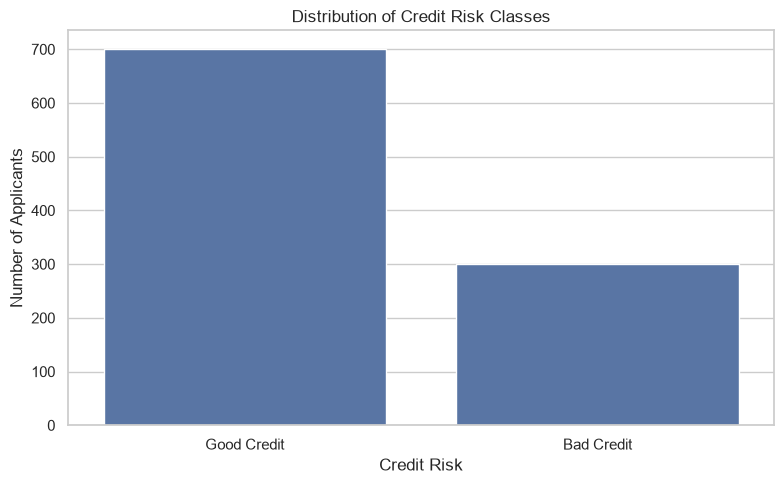

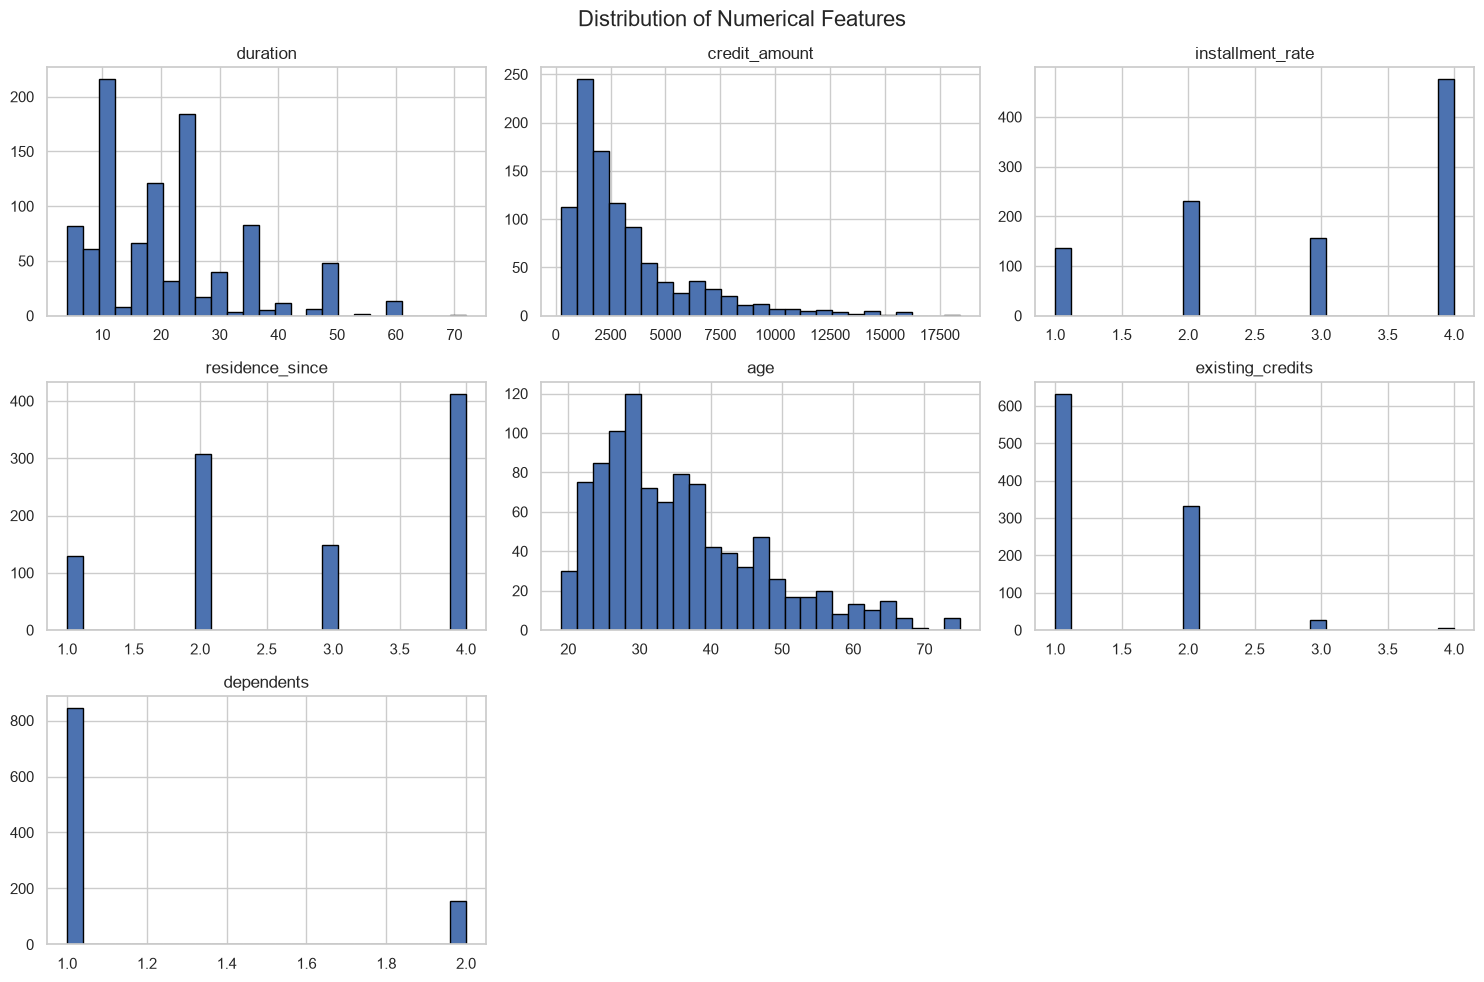

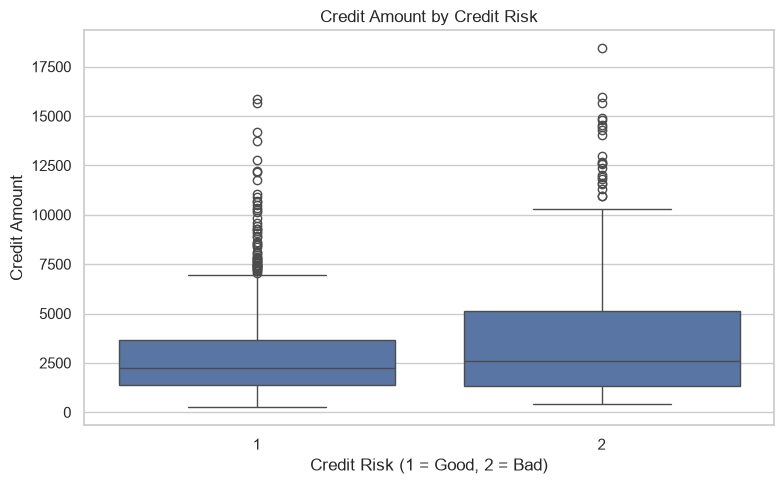

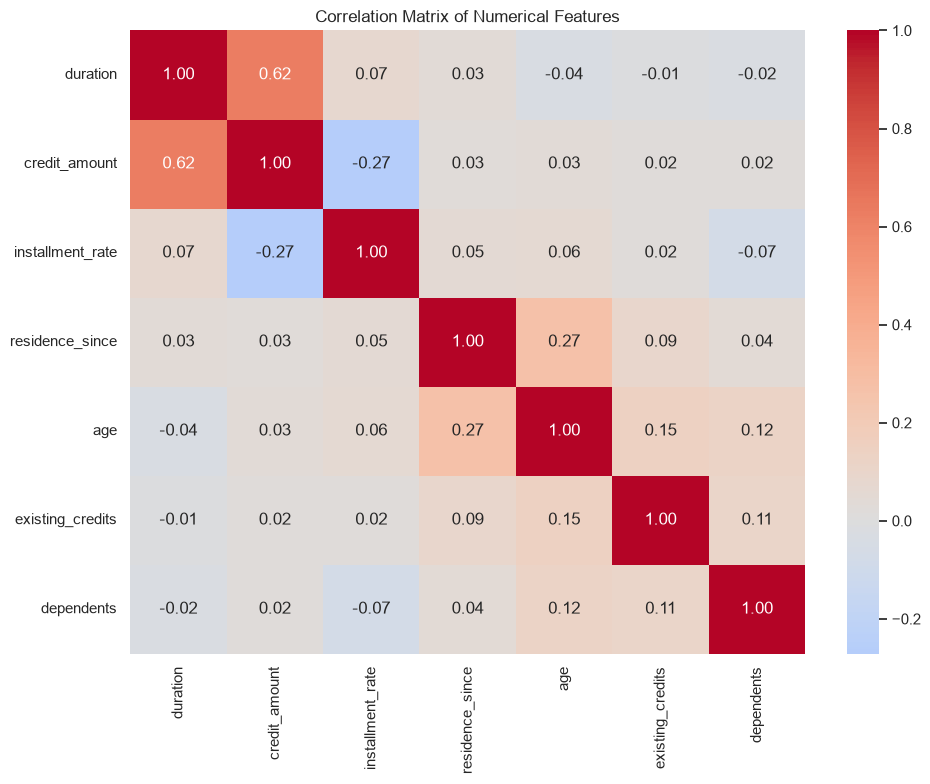

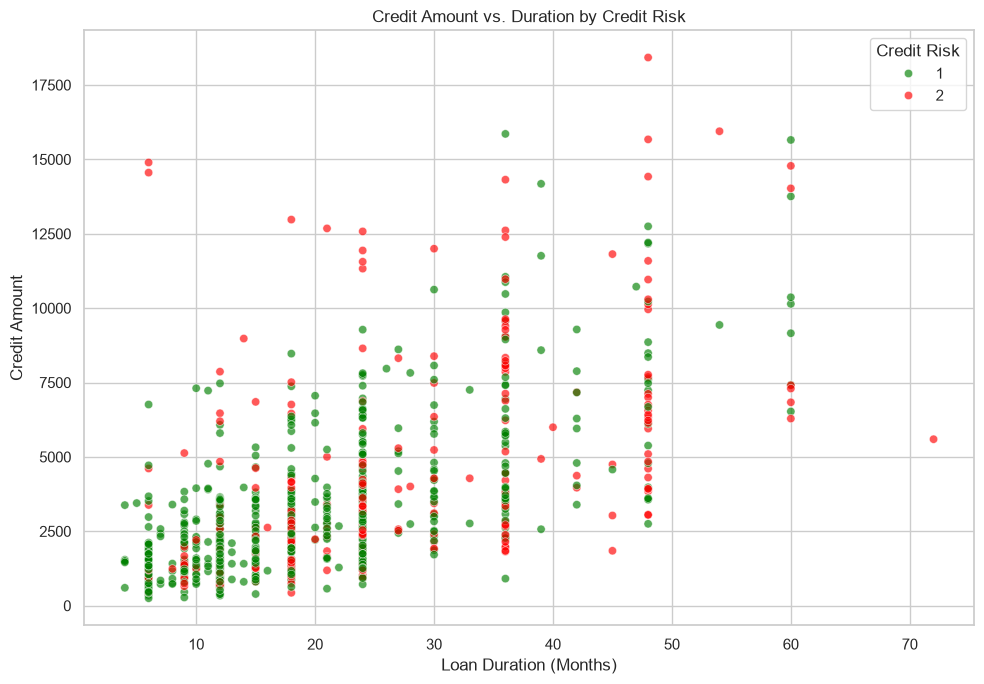

Training samples: 800
Testing samples: 200
Original features: 20
Processed features: 61


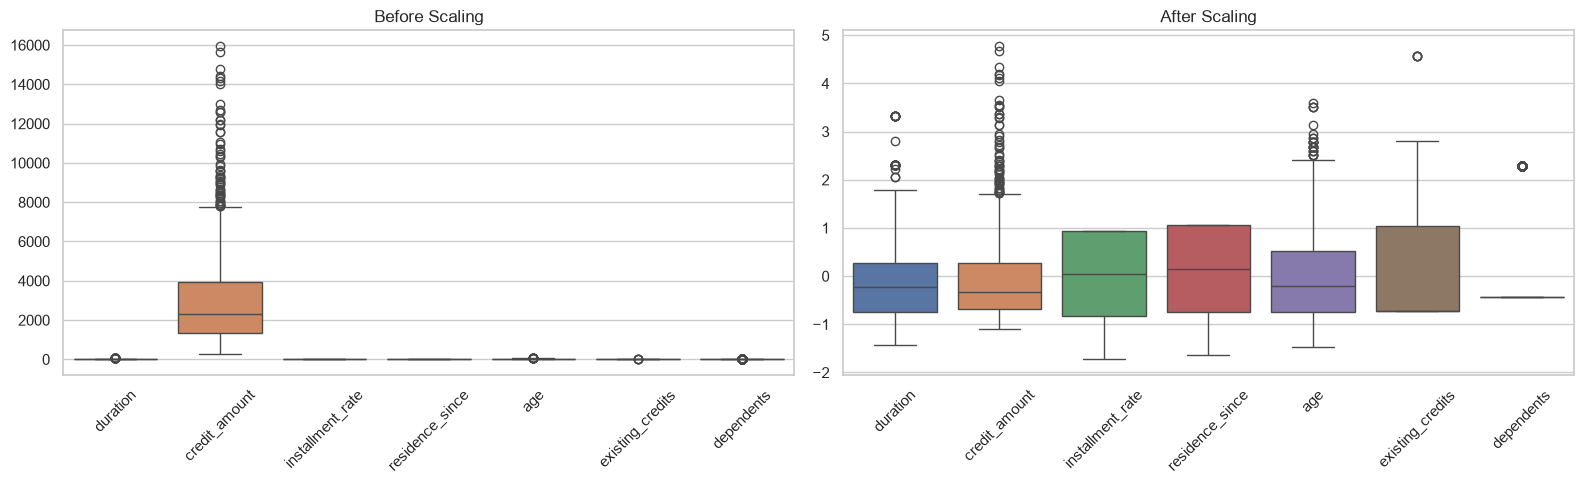

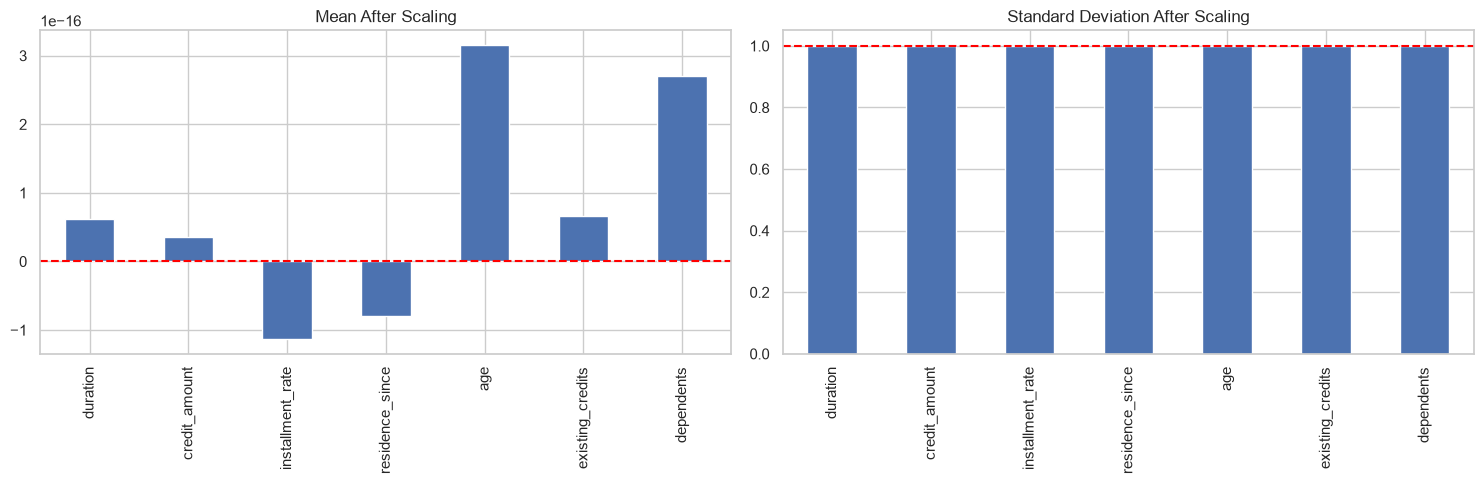

                  Mean  Standard Deviation
duration           0.0                 1.0
credit_amount      0.0                 1.0
installment_rate  -0.0                 1.0
residence_since   -0.0                 1.0
age                0.0                 1.0
existing_credits   0.0                 1.0
dependents         0.0                 1.0


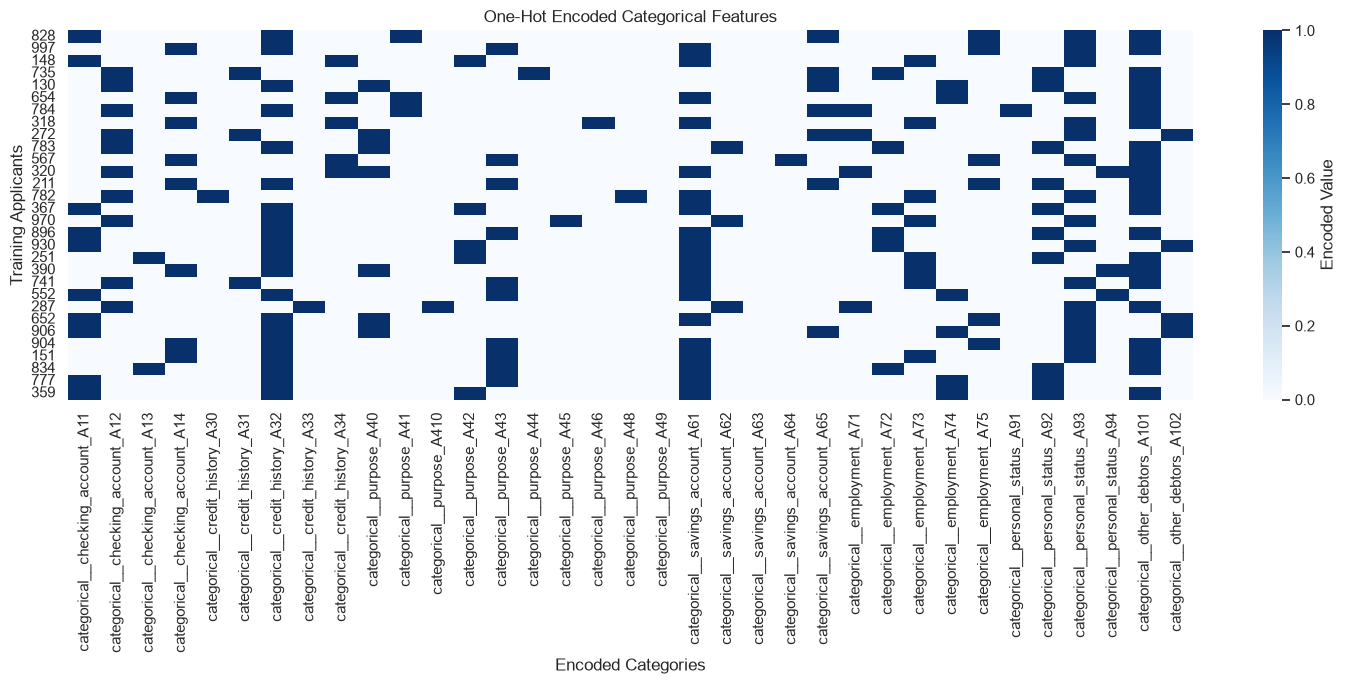

Only 0 and 1: True
Missing values: 0
Best hyperparameters:
{'knn__n_neighbors': 5, 'knn__p': 1, 'knn__weights': 'distance'}

Best cross-validation F1-score:
0.4572
    param_knn__n_neighbors param_knn__weights  param_knn__p  mean_train_score  \
5                        5           distance             1            1.0000   
4                        5            uniform             1            0.6301   
9                        7           distance             1            1.0000   
13                       9           distance             1            1.0000   
7                        5           distance             2            1.0000   
6                        5            uniform             2            0.6063   
0                        3            uniform             1            0.7269   
3                        3           distance             2            1.0000   
1                        3           distance             1            1.0000   
2                        3

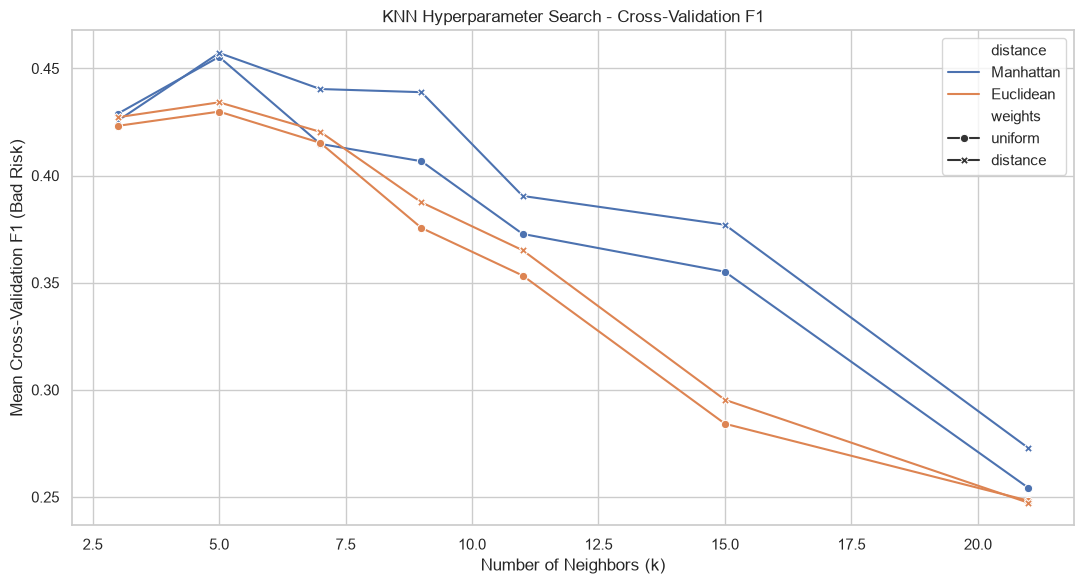

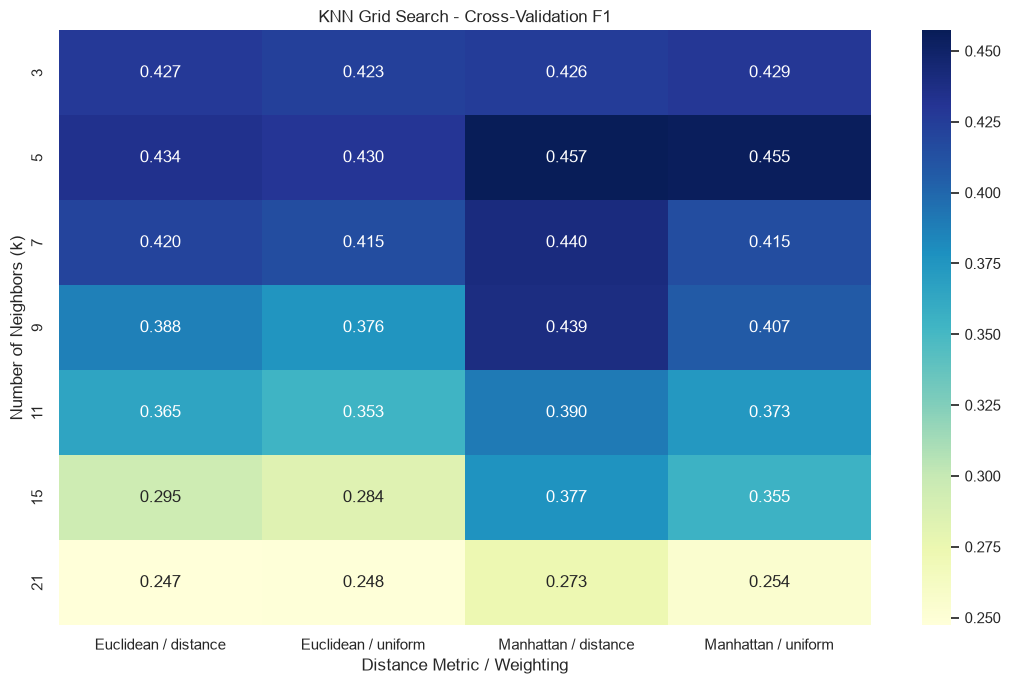

Best parameters: {'knn__n_neighbors': 5, 'knn__p': 1, 'knn__weights': 'distance'}
Correct predictions: 146
Incorrect predictions: 54
      Metric   Score
0   Accuracy  0.7300
1  Precision  0.5750
2     Recall  0.3833
3   F1-score  0.4600

Classification report:
              precision    recall  f1-score   support

 Good Credit       0.77      0.88      0.82       140
  Bad Credit       0.57      0.38      0.46        60

    accuracy                           0.73       200
   macro avg       0.67      0.63      0.64       200
weighted avg       0.71      0.73      0.71       200



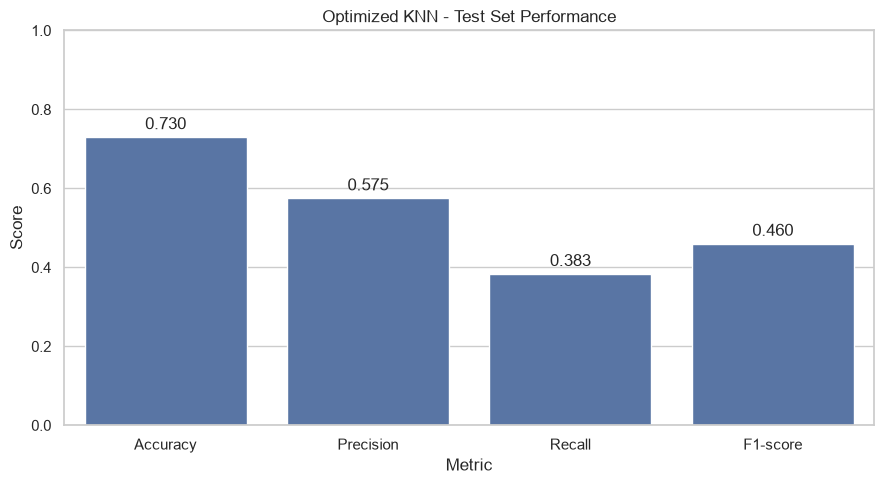

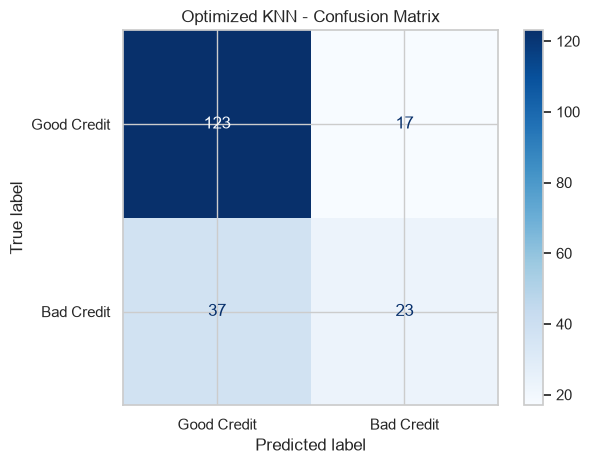

In [ ]:
# ---------------------------------------------------------
# 1. IMPORTS
# ---------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

sns.set_theme(style="whitegrid")


# ---------------------------------------------------------
# 2. LOAD DATASET
# ---------------------------------------------------------

DATA_PATH = Path.cwd() / "data" / "german.data"

column_names = [
    "checking_account",
    "duration",
    "credit_history",
    "purpose",
    "credit_amount",
    "savings_account",
    "employment",
    "installment_rate",
    "personal_status",
    "other_debtors",
    "residence_since",
    "property",
    "age",
    "other_installment_plans",
    "housing",
    "existing_credits",
    "job",
    "dependents",
    "telephone",
    "foreign_worker",
    "credit_risk",
]

df = pd.read_csv(DATA_PATH, sep=r"\s+", header=None, names=column_names)

X = df.drop(columns=["credit_risk"])
y = df["credit_risk"]

print("Dataset:", df.shape)
print("Features:", X.shape)
print("Target:", y.shape)


# ---------------------------------------------------------
# 3. INITIAL DATA INSPECTION
# ---------------------------------------------------------

numeric_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print("Missing values:", X.isna().sum().sum())
print("Duplicate rows:", X.duplicated().sum())

print("\nTarget distribution:")
print(y.value_counts().sort_index())

feature_summary = pd.DataFrame(
    {
        "Type": X.dtypes.astype(str),
        "Missing": X.isna().sum(),
        "Unique values": X.nunique(),
    }
)

print("\nFeature summary:")
print(feature_summary)


# ---------------------------------------------------------
# 4. EXPLORATORY DATA ANALYSIS
# ---------------------------------------------------------

# 4.1 Target distribution

class_counts = y.value_counts().sort_index()

plt.figure(figsize=(8, 5))

sns.barplot(x=["Good Credit", "Bad Credit"], y=class_counts.values)

plt.title("Distribution of Credit Risk Classes")
plt.xlabel("Credit Risk")
plt.ylabel("Number of Applicants")

plt.tight_layout()
plt.show()


# 4.2 Numerical feature distributions

X[numeric_features].hist(figsize=(15, 10), bins=25, edgecolor="black")

plt.suptitle("Distribution of Numerical Features", fontsize=16)

plt.tight_layout()
plt.show()


# 4.3 Credit amount by credit risk

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="credit_risk", y="credit_amount", order=[1, 2])

plt.title("Credit Amount by Credit Risk")
plt.xlabel("Credit Risk (1 = Good, 2 = Bad)")
plt.ylabel("Credit Amount")

plt.tight_layout()
plt.show()


# 4.4 Correlation heatmap

correlation_matrix = X[numeric_features].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", center=0)

plt.title("Correlation Matrix of Numerical Features")

plt.tight_layout()
plt.show()

# 4.5 Credit amount vs. duration

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="duration",
    y="credit_amount",
    hue="credit_risk",
    palette={1: "green", 2: "red"},
    alpha=0.65,
)

plt.title("Credit Amount vs. Duration by Credit Risk")
plt.xlabel("Loan Duration (Months)")
plt.ylabel("Credit Amount")
plt.legend(title="Credit Risk")

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 5. TRAIN / TEST SPLIT
# ---------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


# ---------------------------------------------------------
# 6. PREPROCESSING
# ---------------------------------------------------------

numeric_pipeline = Pipeline(
    [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
)

categorical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocessor = ColumnTransformer(
    [
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ]
)


# 6.1 Apply preprocessing

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_processed_df = pd.DataFrame(
    X_train_processed, columns=feature_names, index=X_train.index
)

X_test_processed_df = pd.DataFrame(
    X_test_processed, columns=feature_names, index=X_test.index
)

print("Original features:", X_train.shape[1])
print("Processed features:", X_train_processed_df.shape[1])

# ---------------------------------------------------------
# 7. PREPROCESSING VERIFICATION
# ---------------------------------------------------------

# 7.1 Compare distributions before and after scaling

original_numeric = X_train[numeric_features]

scaled_numeric = pd.DataFrame(
    X_train_processed[:, : len(numeric_features)],
    columns=numeric_features,
    index=X_train.index,
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(data=original_numeric, ax=axes[0])
axes[0].set_title("Before Scaling")
axes[0].tick_params(axis="x", rotation=45)

sns.boxplot(data=scaled_numeric, ax=axes[1])
axes[1].set_title("After Scaling")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# 7.2 Scaling verification

scaling_summary = pd.DataFrame(
    {"Mean": scaled_numeric.mean(), "Standard Deviation": scaled_numeric.std(ddof=0)}
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

scaling_summary["Mean"].plot(kind="bar", ax=axes[0], title="Mean After Scaling")

scaling_summary["Standard Deviation"].plot(
    kind="bar", ax=axes[1], title="Standard Deviation After Scaling"
)

axes[0].axhline(0, color="red", linestyle="--")
axes[1].axhline(1, color="red", linestyle="--")

plt.tight_layout()
plt.show()

print(scaling_summary.round(3))


# 7.3 Categorical encoding verification

encoded_columns = [
    col for col in X_train_processed_df.columns if col.startswith("categorical__")
]

encoded_df = X_train_processed_df[encoded_columns]

plt.figure(figsize=(15, 7))

sns.heatmap(
    encoded_df.iloc[:30, :35],
    cmap="Blues",
    vmin=0,
    vmax=1,
    cbar_kws={"label": "Encoded Value"},
)

plt.title("One-Hot Encoded Categorical Features")
plt.xlabel("Encoded Categories")
plt.ylabel("Training Applicants")

plt.tight_layout()
plt.show()

print("Only 0 and 1:", encoded_df.isin([0, 1]).all().all())
print("Missing values:", X_train_processed_df.isna().sum().sum())


# ---------------------------------------------------------
# 8. MODEL TRAINING - GRID SEARCH
# ---------------------------------------------------------

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, f1_score
from sklearn.neighbors import KNeighborsClassifier

model_pipeline = Pipeline(
    [("preprocessor", preprocessor), ("knn", KNeighborsClassifier())]
)


# 8.1 Hyperparameter grid

param_grid = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],
}
# 8.2 Cross-validation and Grid Search

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=model_pipeline,
    param_grid=param_grid,
    scoring=make_scorer(f1_score, pos_label=2),
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
    refit=True,
)

grid_search.fit(X_train, y_train)

print("Best hyperparameters:")
print(grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(grid_search.best_score_, 4))


# ---------------------------------------------------------
# 9. GRID SEARCH RESULTS
# ---------------------------------------------------------

cv_results = pd.DataFrame(grid_search.cv_results_)

results_summary = cv_results[
    [
        "param_knn__n_neighbors",
        "param_knn__weights",
        "param_knn__p",
        "mean_train_score",
        "mean_test_score",
        "std_test_score",
        "rank_test_score",
    ]
].sort_values("rank_test_score")

print(results_summary.head(10).round(4))

# 9.1 Cross-validation performance vs. k

plot_results = cv_results.copy()

plot_results["k"] = plot_results["param_knn__n_neighbors"].astype(int)
plot_results["weights"] = plot_results["param_knn__weights"].astype(str)
plot_results["distance"] = plot_results["param_knn__p"].map(
    {1: "Manhattan", 2: "Euclidean"}
)

plt.figure(figsize=(11, 6))

sns.lineplot(
    data=plot_results,
    x="k",
    y="mean_test_score",
    hue="distance",
    style="weights",
    markers=True,
    dashes=False,
)

plt.title("KNN Hyperparameter Search - Cross-Validation F1")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Mean Cross-Validation F1 (Bad Risk)")

plt.tight_layout()
plt.show()
# 9.2 Hyperparameter heatmap

plot_results["configuration"] = (
    plot_results["distance"] + " / " + plot_results["weights"]
)

heatmap_data = plot_results.pivot(
    index="k", columns="configuration", values="mean_test_score"
)

plt.figure(figsize=(11, 7))

sns.heatmap(heatmap_data, annot=True, fmt=".3f", cmap="YlGnBu")

plt.title("KNN Grid Search - Cross-Validation F1")
plt.xlabel("Distance Metric / Weighting")
plt.ylabel("Number of Neighbors (k)")

plt.tight_layout()
plt.show()
# ---------------------------------------------------------
# 10. FINAL MODEL PREDICTIONS
# ---------------------------------------------------------

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

results = X_test.copy()

results["Actual"] = y_test
results["Predicted"] = y_pred
results["Correct"] = y_test == y_pred

print("Best parameters:", grid_search.best_params_)
print("Correct predictions:", results["Correct"].sum())
print("Incorrect predictions:", (~results["Correct"]).sum())


# 10.1 Final evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    ConfusionMatrixDisplay,
)

metrics = pd.DataFrame(
    {
        "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
        "Score": [
            accuracy_score(y_test, y_pred),
            precision_score(y_test, y_pred, pos_label=2),
            recall_score(y_test, y_pred, pos_label=2),
            f1_score(y_test, y_pred, pos_label=2),
        ],
    }
)

print(metrics.round(4))

print("\nClassification report:")
print(
    classification_report(
        y_test, y_pred, labels=[1, 2], target_names=["Good Credit", "Bad Credit"]
    )
)


# 10.2 Evaluation metrics plot

plt.figure(figsize=(9, 5))

sns.barplot(data=metrics, x="Metric", y="Score")

plt.title("Optimized KNN - Test Set Performance")
plt.ylabel("Score")
plt.ylim(0, 1)

for i, score in enumerate(metrics["Score"]):
    plt.text(i, min(score + 0.02, 0.98), f"{score:.3f}", ha="center")

plt.tight_layout()
plt.show()


# 10.3 Confusion matrix

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[1, 2],
    display_labels=["Good Credit", "Bad Credit"],
    cmap="Blues",
    values_format="d",
)

plt.title("Optimized KNN - Confusion Matrix")
plt.tight_layout()
plt.show()

Dataset shape: (1000, 21)
Features: (1000, 20)
Target: (1000,)
                          Type  Missing  Unique
checking_account           str        0       4
duration                 int64        0      33
credit_history             str        0       5
purpose                    str        0      10
credit_amount            int64        0     921
savings_account            str        0       5
employment                 str        0       5
installment_rate         int64        0       4
personal_status            str        0       4
other_debtors              str        0       3
residence_since          int64        0       4
property                   str        0       4
age                      int64        0      53
other_installment_plans    str        0       3
housing                    str        0       3
existing_credits         int64        0       4
job                        str        0       4
dependents               int64        0       2
telephone                

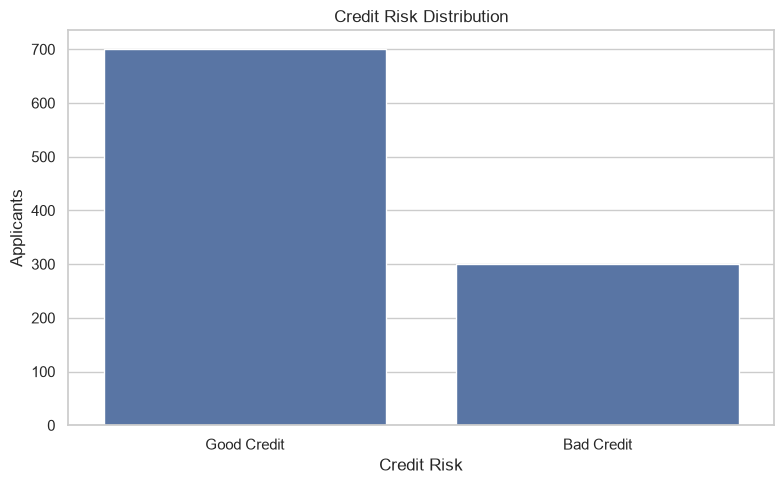

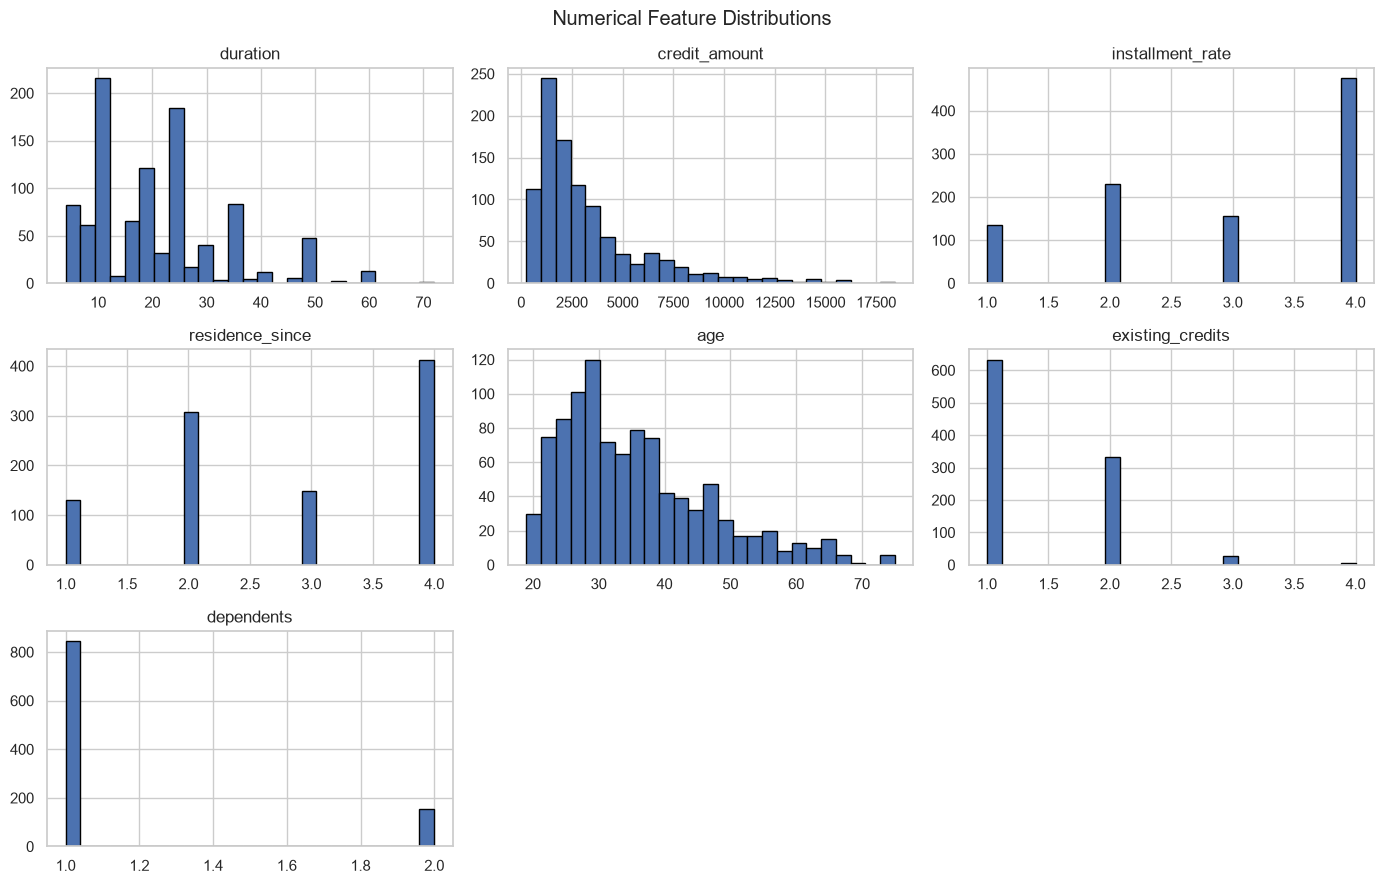

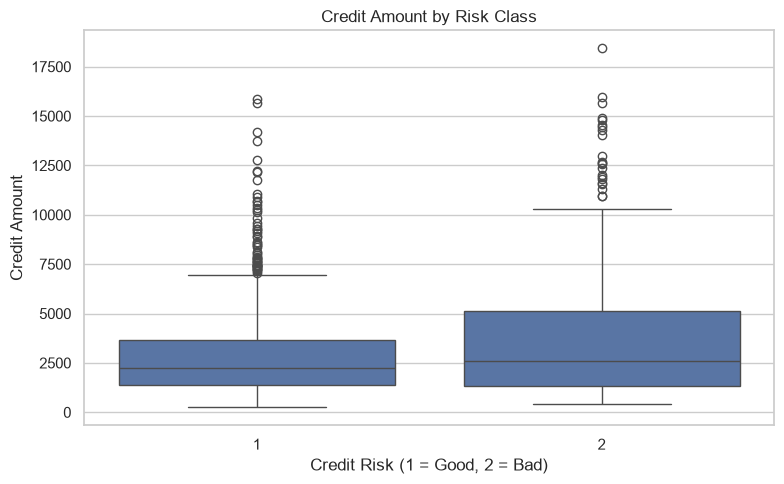

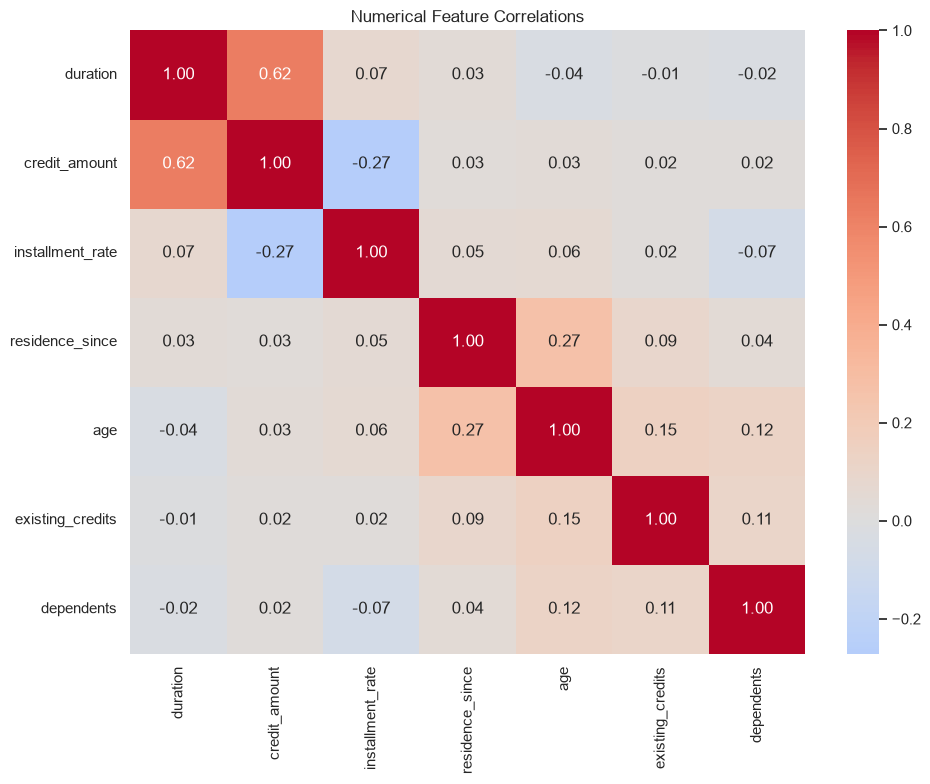

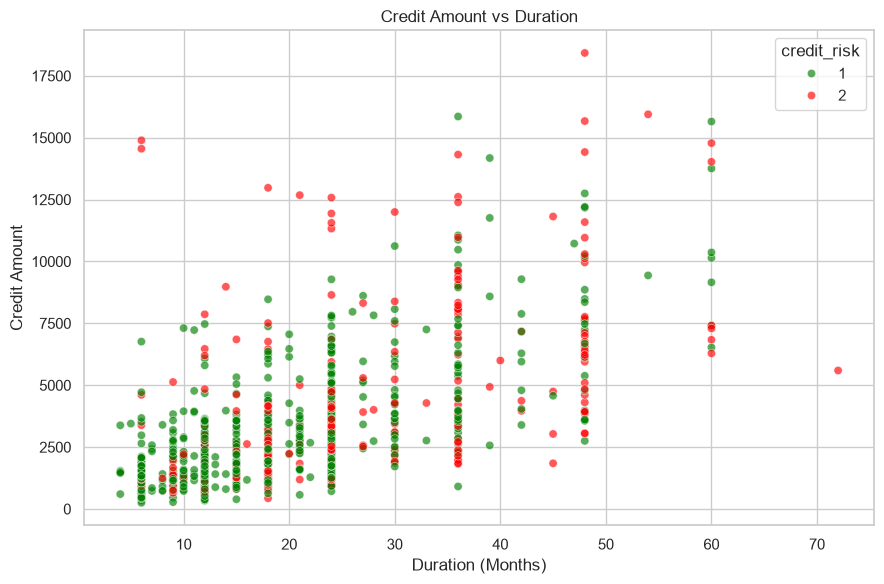

Training samples: 800
Testing samples: 200
Features before: 20
Features after: 61


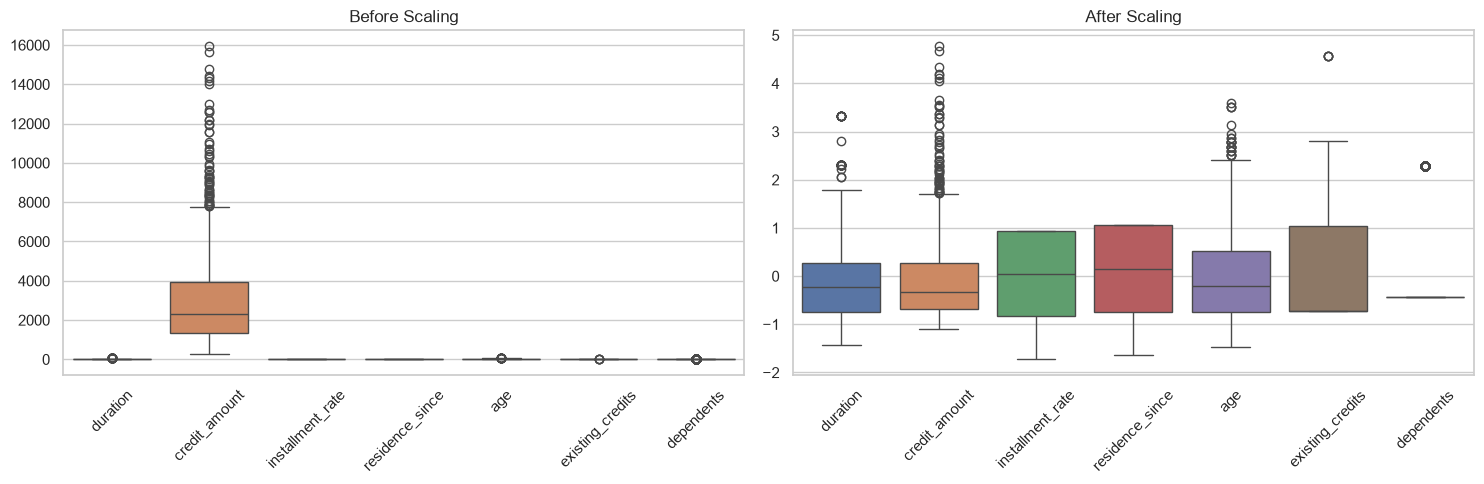

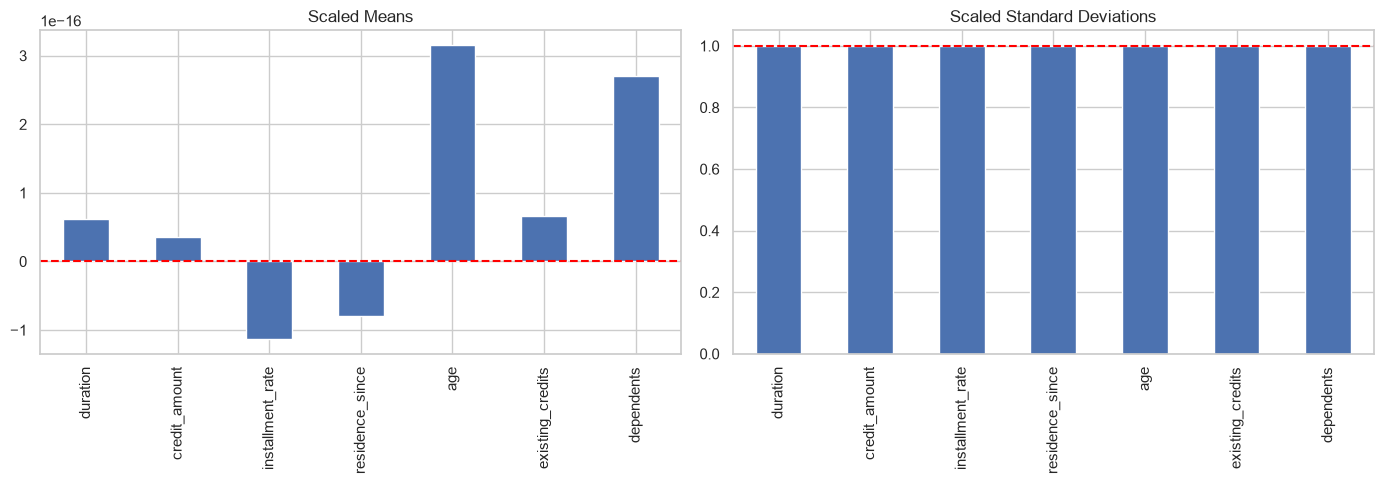

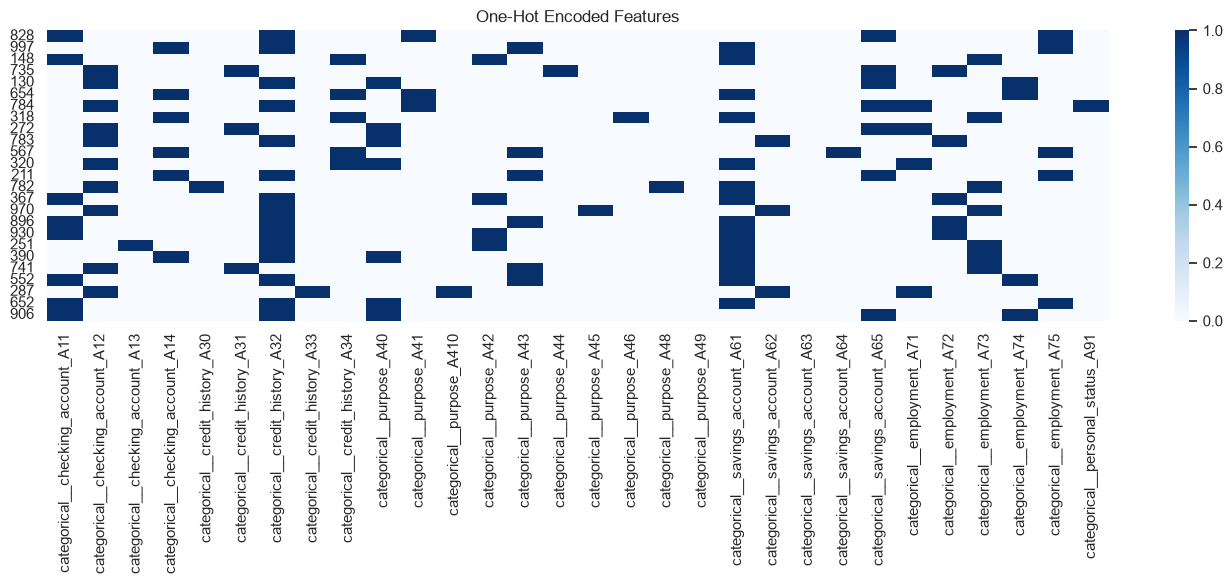

Only 0 and 1: True
Missing values: 0
Best parameters: {'knn__n_neighbors': 5, 'knn__p': 1, 'knn__weights': 'distance'}
Best CV F1: 0.4572

Best configurations by F1:
    k   weights   distance  mean_test_bad_f1  mean_test_accuracy  \
5   5  distance  Manhattan             0.457               0.745   
4   5   uniform  Manhattan             0.455               0.746   
9   7  distance  Manhattan             0.440               0.753   
13  9  distance  Manhattan             0.439               0.754   
7   5  distance  Euclidean             0.434               0.744   
6   5   uniform  Euclidean             0.430               0.742   
0   3   uniform  Manhattan             0.429               0.736   
3   3  distance  Euclidean             0.427               0.726   
1   3  distance  Manhattan             0.426               0.732   
2   3   uniform  Euclidean             0.423               0.725   

    mean_test_balanced_accuracy  
5                         0.635  
4                

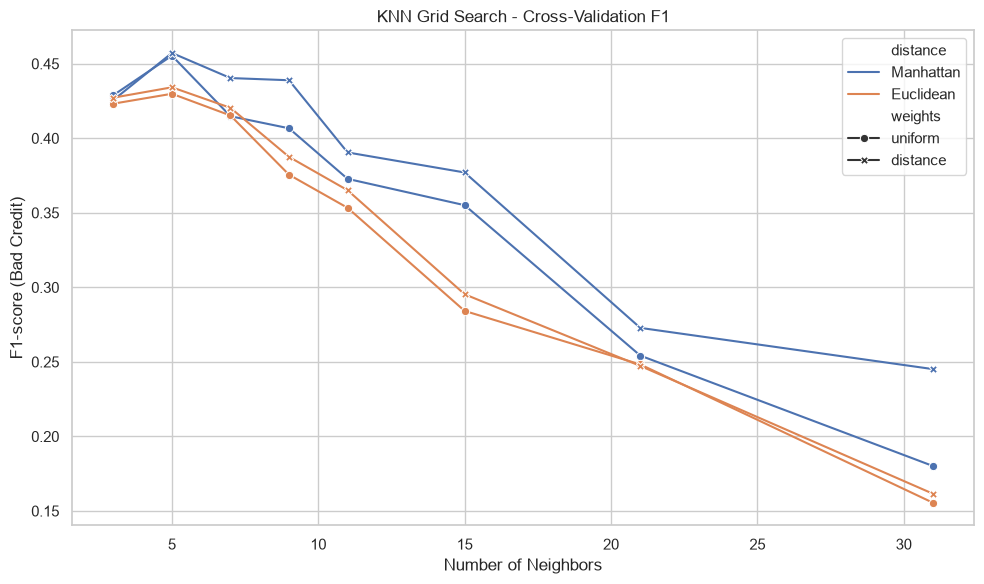

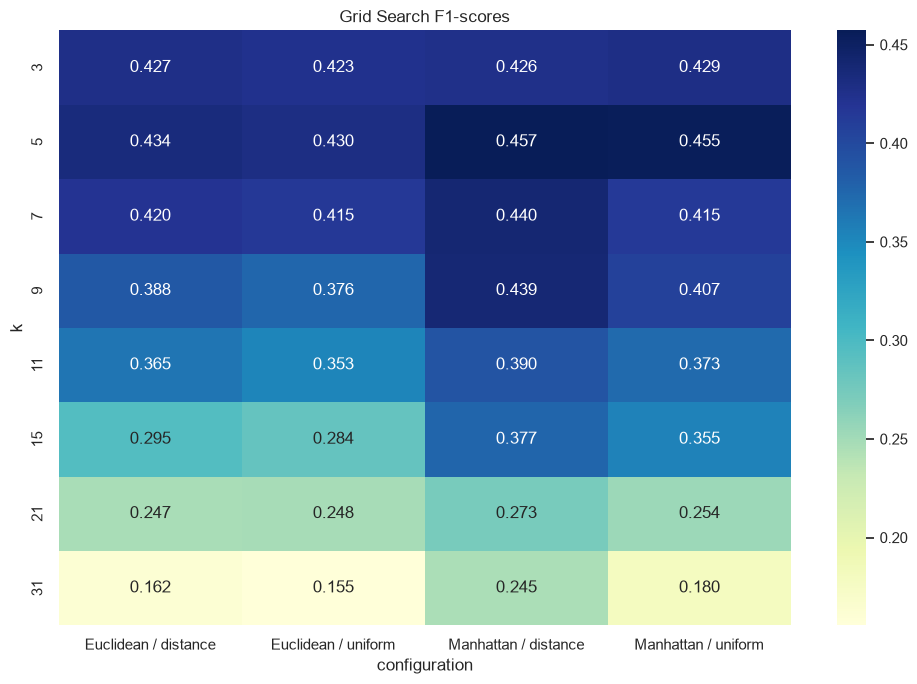

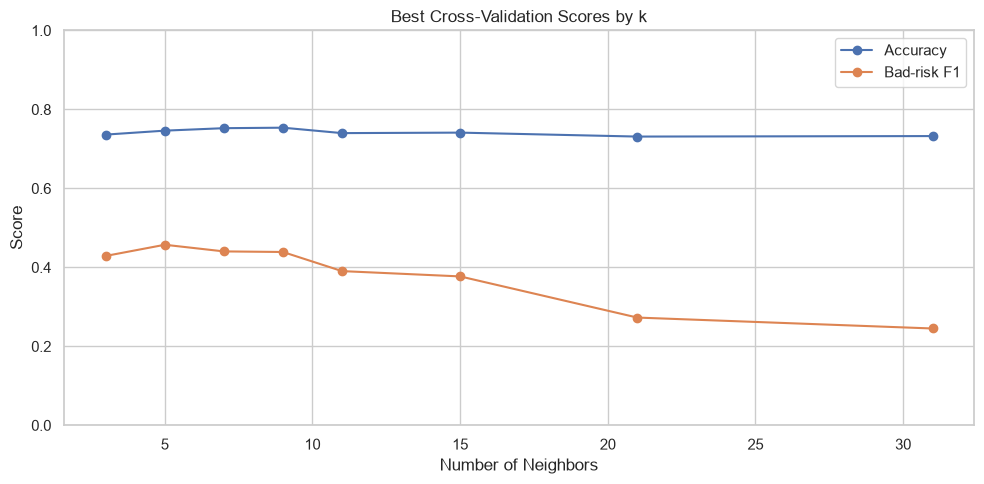


Final test results:
      Metric   Score
0   Accuracy  0.7300
1  Precision  0.5750
2     Recall  0.3833
3         F1  0.4600

Classification report:
              precision    recall  f1-score   support

 Good Credit       0.77      0.88      0.82       140
  Bad Credit       0.57      0.38      0.46        60

    accuracy                           0.73       200
   macro avg       0.67      0.63      0.64       200
weighted avg       0.71      0.73      0.71       200


Majority-class baseline accuracy: 0.7


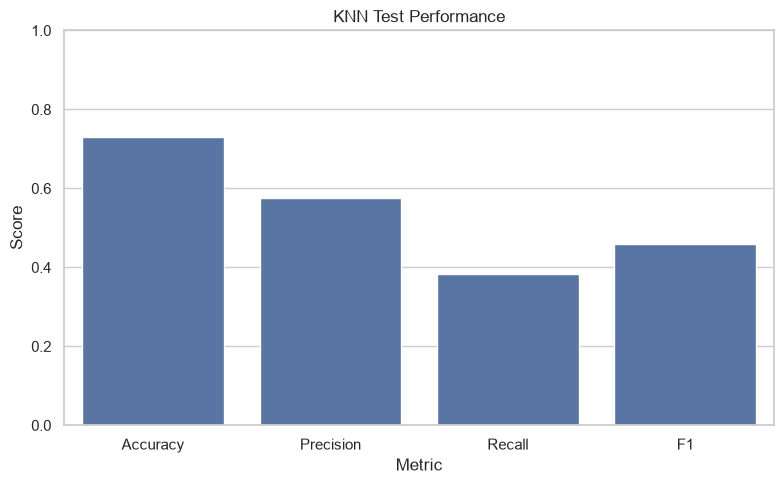

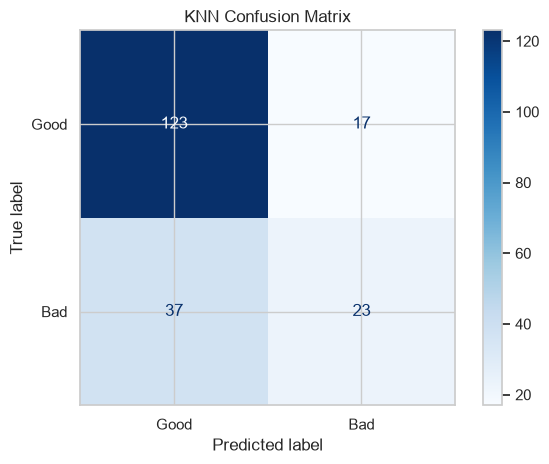

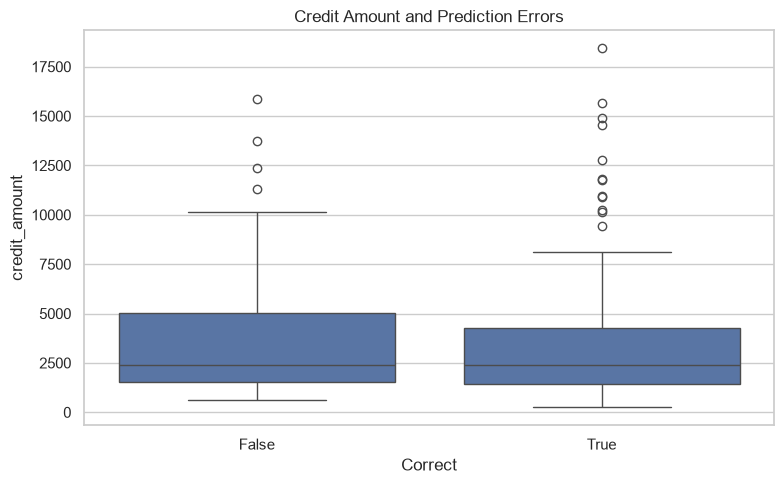

In [ ]:
# ---------------------------------------------------------
# 1. Imports
# ---------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
    make_scorer,
)

sns.set_theme(style="whitegrid")


# ---------------------------------------------------------
# 2. Load dataset
# ---------------------------------------------------------

DATA_PATH = Path.cwd() / "data" / "german.data"

column_names = [
    "checking_account",
    "duration",
    "credit_history",
    "purpose",
    "credit_amount",
    "savings_account",
    "employment",
    "installment_rate",
    "personal_status",
    "other_debtors",
    "residence_since",
    "property",
    "age",
    "other_installment_plans",
    "housing",
    "existing_credits",
    "job",
    "dependents",
    "telephone",
    "foreign_worker",
    "credit_risk",
]

df = pd.read_csv(DATA_PATH, sep=r"\s+", header=None, names=column_names)

X = df.drop(columns="credit_risk")
y = df["credit_risk"]

print("Dataset shape:", df.shape)
print("Features:", X.shape)
print("Target:", y.shape)


# ---------------------------------------------------------
# 3. Data inspection
# ---------------------------------------------------------

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

feature_summary = pd.DataFrame(
    {"Type": X.dtypes.astype(str), "Missing": X.isna().sum(), "Unique": X.nunique()}
)

print(feature_summary)
print("\nMissing values:", X.isna().sum().sum())
print("Duplicate rows:", X.duplicated().sum())
print("\nTarget distribution:")
print(y.value_counts().sort_index())


# ---------------------------------------------------------
# 4. Exploratory data analysis
# ---------------------------------------------------------

# Credit risk distribution

class_counts = y.value_counts().sort_index()

plt.figure(figsize=(8, 5))
sns.barplot(x=["Good Credit", "Bad Credit"], y=class_counts.values)
plt.title("Credit Risk Distribution")
plt.xlabel("Credit Risk")
plt.ylabel("Applicants")
plt.tight_layout()
plt.show()


# Numerical feature distributions

X[numeric_features].hist(figsize=(14, 9), bins=25, edgecolor="black")
plt.suptitle("Numerical Feature Distributions")
plt.tight_layout()
plt.show()


# Credit amount by risk class

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="credit_risk", y="credit_amount", order=[1, 2])
plt.title("Credit Amount by Risk Class")
plt.xlabel("Credit Risk (1 = Good, 2 = Bad)")
plt.ylabel("Credit Amount")
plt.tight_layout()
plt.show()


# Correlations between numerical features

plt.figure(figsize=(10, 8))
sns.heatmap(
    X[numeric_features].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0
)
plt.title("Numerical Feature Correlations")
plt.tight_layout()
plt.show()


# Credit amount and duration

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="duration",
    y="credit_amount",
    hue="credit_risk",
    palette={1: "green", 2: "red"},
    alpha=0.65,
)
plt.title("Credit Amount vs Duration")
plt.xlabel("Duration (Months)")
plt.ylabel("Credit Amount")
plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 5. Train/test split
# ---------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


# ---------------------------------------------------------
# 6. Preprocessing
# ---------------------------------------------------------

numeric_pipeline = Pipeline(
    [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
)

categorical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocessor = ColumnTransformer(
    [
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ]
)

# Fit a preprocessing copy for inspection.
# GridSearchCV will fit preprocessing independently in each fold.

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

processed_train = pd.DataFrame(
    X_train_processed, columns=feature_names, index=X_train.index
)

print("Features before:", X_train.shape[1])
print("Features after:", processed_train.shape[1])


# ---------------------------------------------------------
# 7. Check preprocessing
# ---------------------------------------------------------

scaled_numeric = processed_train[
    [col for col in feature_names if col.startswith("numeric__")]
].copy()

scaled_numeric.columns = numeric_features

encoded_data = processed_train[
    [col for col in feature_names if col.startswith("categorical__")]
]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=X_train[numeric_features], ax=axes[0])
axes[0].set_title("Before Scaling")
axes[0].tick_params(axis="x", rotation=45)

sns.boxplot(data=scaled_numeric, ax=axes[1])
axes[1].set_title("After Scaling")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


# Check scaled means and standard deviations

scaling_summary = pd.DataFrame(
    {"Mean": scaled_numeric.mean(), "Std": scaled_numeric.std(ddof=0)}
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

scaling_summary["Mean"].plot.bar(ax=axes[0], title="Scaled Means")
scaling_summary["Std"].plot.bar(ax=axes[1], title="Scaled Standard Deviations")

axes[0].axhline(0, color="red", linestyle="--")
axes[1].axhline(1, color="red", linestyle="--")

plt.tight_layout()
plt.show()


# Visualize one-hot encoding

plt.figure(figsize=(14, 6))

sns.heatmap(encoded_data.iloc[:25, :30], cmap="Blues", vmin=0, vmax=1)

plt.title("One-Hot Encoded Features")
plt.tight_layout()
plt.show()

print("Only 0 and 1:", encoded_data.isin([0, 1]).all().all())
print("Missing values:", processed_train.isna().sum().sum())


# ---------------------------------------------------------
# 8. KNN training and Grid Search
# ---------------------------------------------------------

model = Pipeline([("preprocessor", preprocessor), ("knn", KNeighborsClassifier())])

param_grid = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "bad_f1": make_scorer(f1_score, pos_label=2),
    "balanced_accuracy": "balanced_accuracy",
}

grid_search = GridSearchCV(
    model, param_grid, scoring=scoring, refit="bad_f1", cv=cv, n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV F1:", round(grid_search.best_score_, 4))


# Analyze all hyperparameter combinations

cv_results = pd.DataFrame(grid_search.cv_results_)

cv_results["k"] = cv_results["param_knn__n_neighbors"].astype(int)
cv_results["weights"] = cv_results["param_knn__weights"].astype(str)
cv_results["distance"] = cv_results["param_knn__p"].map(
    {1: "Manhattan", 2: "Euclidean"}
)

print("\nBest configurations by F1:")
print(
    cv_results[
        [
            "k",
            "weights",
            "distance",
            "mean_test_bad_f1",
            "mean_test_accuracy",
            "mean_test_balanced_accuracy",
        ]
    ]
    .sort_values("mean_test_bad_f1", ascending=False)
    .head(10)
    .round(3)
)


# F1-score for different values of k

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=cv_results,
    x="k",
    y="mean_test_bad_f1",
    hue="distance",
    style="weights",
    markers=True,
    dashes=False,
    estimator=None,
)

plt.title("KNN Grid Search - Cross-Validation F1")
plt.xlabel("Number of Neighbors")
plt.ylabel("F1-score (Bad Credit)")
plt.tight_layout()
plt.show()


# F1-score heatmap

cv_results["configuration"] = cv_results["distance"] + " / " + cv_results["weights"]

heatmap_data = cv_results.pivot(
    index="k", columns="configuration", values="mean_test_bad_f1"
)

plt.figure(figsize=(10, 7))
sns.heatmap(heatmap_data, annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("Grid Search F1-scores")
plt.tight_layout()
plt.show()


# Compare accuracy and F1 during cross-validation

score_comparison = (
    cv_results.groupby("k")[["mean_test_accuracy", "mean_test_bad_f1"]]
    .max()
    .rename(
        columns={"mean_test_accuracy": "Accuracy", "mean_test_bad_f1": "Bad-risk F1"}
    )
)

score_comparison.plot(marker="o", figsize=(10, 5))
plt.title("Best Cross-Validation Scores by k")
plt.xlabel("Number of Neighbors")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 9. Final evaluation
# ---------------------------------------------------------

best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=2)
recall = recall_score(y_test, y_pred, pos_label=2)
f1 = f1_score(y_test, y_pred, pos_label=2)

metrics = pd.DataFrame(
    {
        "Metric": ["Accuracy", "Precision", "Recall", "F1"],
        "Score": [accuracy, precision, recall, f1],
    }
)

print("\nFinal test results:")
print(metrics.round(4))

print("\nClassification report:")
print(
    classification_report(
        y_test, y_pred, labels=[1, 2], target_names=["Good Credit", "Bad Credit"]
    )
)


# Compare against a simple majority-class baseline

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

print(
    "\nMajority-class baseline accuracy:",
    round(accuracy_score(y_test, baseline_pred), 4),
)


# Evaluation metrics plot

plt.figure(figsize=(8, 5))
sns.barplot(data=metrics, x="Metric", y="Score")
plt.title("KNN Test Performance")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


# Confusion matrix

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=[1, 2], display_labels=["Good", "Bad"], cmap="Blues"
)

plt.title("KNN Confusion Matrix")
plt.tight_layout()
plt.show()


# Inspect incorrect predictions

predictions = X_test.copy()
predictions["Actual"] = y_test
predictions["Predicted"] = y_pred
predictions["Correct"] = y_test == y_pred

plt.figure(figsize=(8, 5))
sns.boxplot(data=predictions, x="Correct", y="credit_amount")
plt.title("Credit Amount and Prediction Errors")
plt.tight_layout()
plt.show()

Dataset shape: (1000, 21)
Features: (1000, 20)
Target: (1000,)
                          Type  Missing  Unique
checking_account           str        0       4
duration                 int64        0      33
credit_history             str        0       5
purpose                    str        0      10
credit_amount            int64        0     921
savings_account            str        0       5
employment                 str        0       5
installment_rate         int64        0       4
personal_status            str        0       4
other_debtors              str        0       3
residence_since          int64        0       4
property                   str        0       4
age                      int64        0      53
other_installment_plans    str        0       3
housing                    str        0       3
existing_credits         int64        0       4
job                        str        0       4
dependents               int64        0       2
telephone                

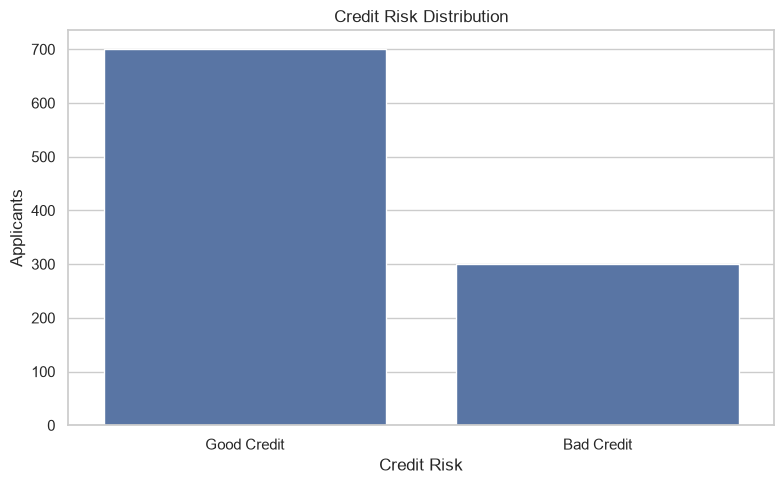

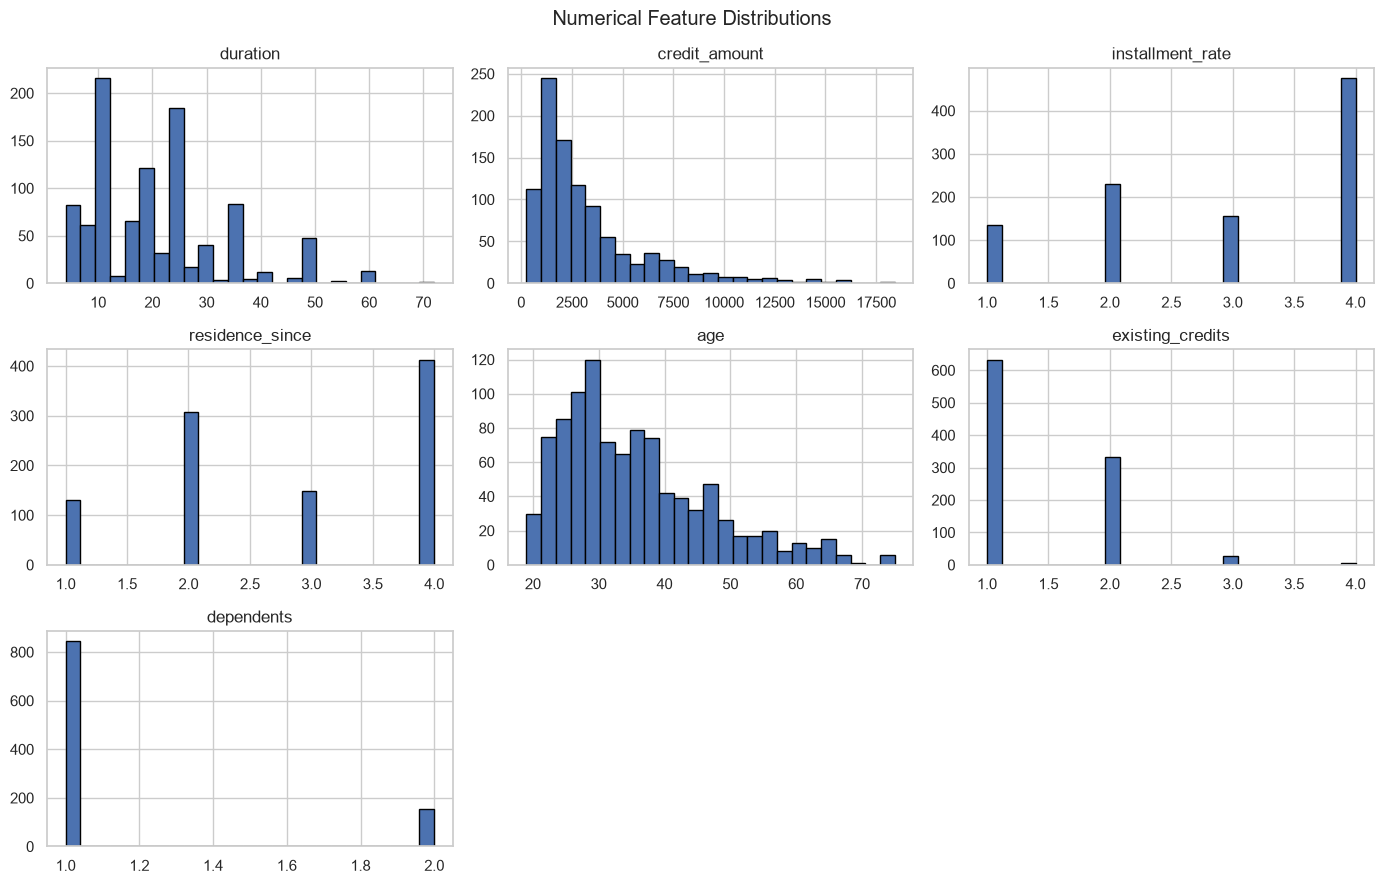

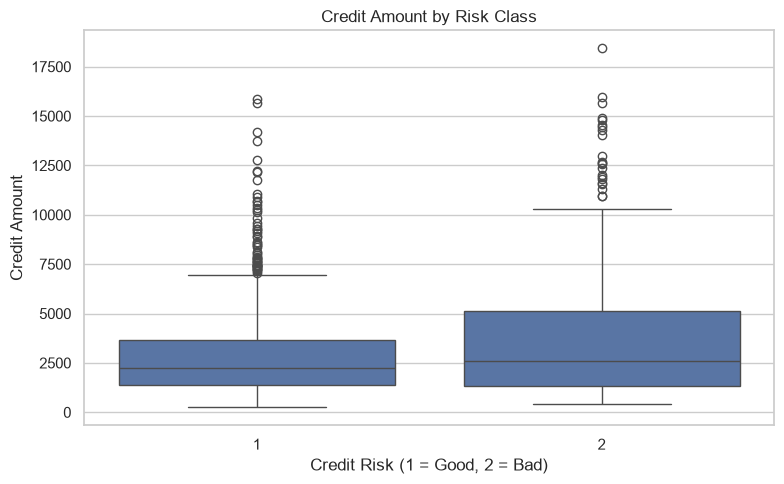

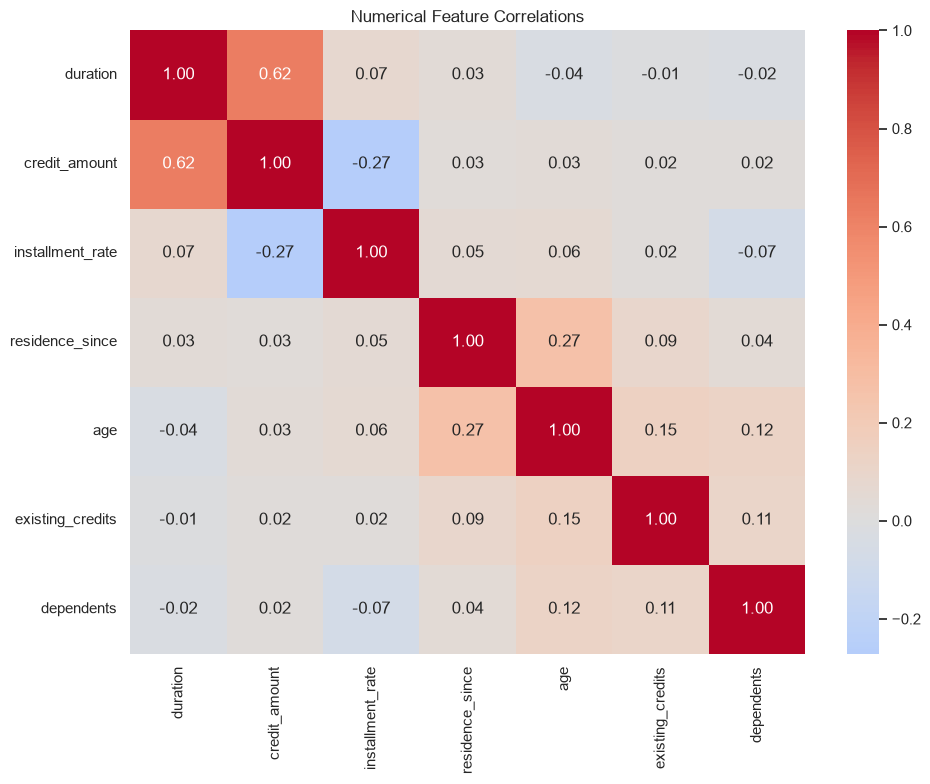

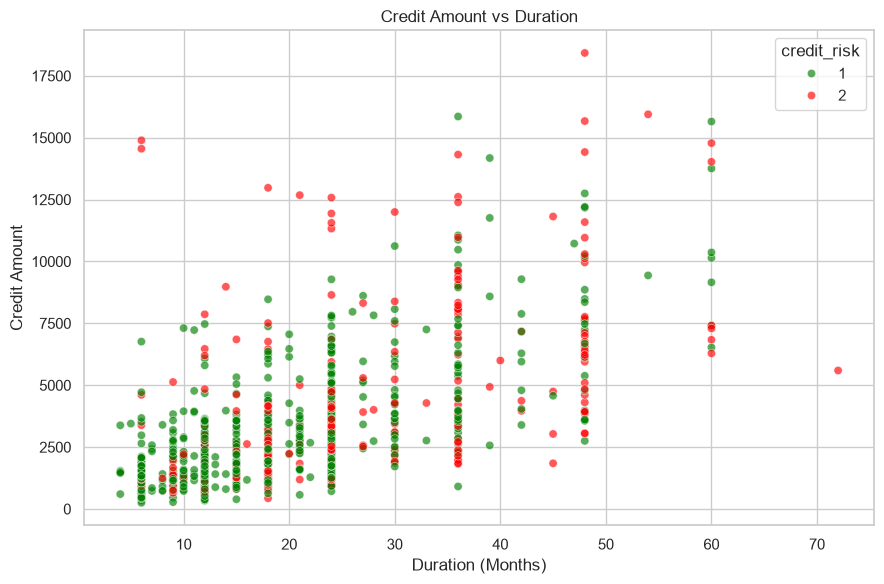

Training samples: 800
Testing samples: 200
Features before: 20
Features after: 61


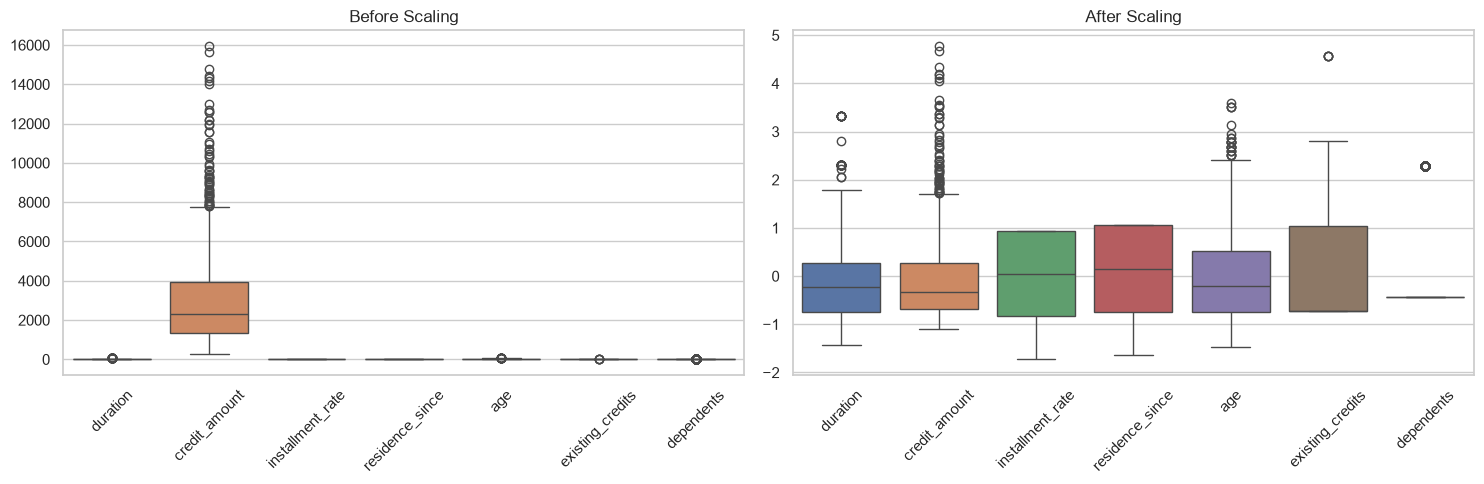

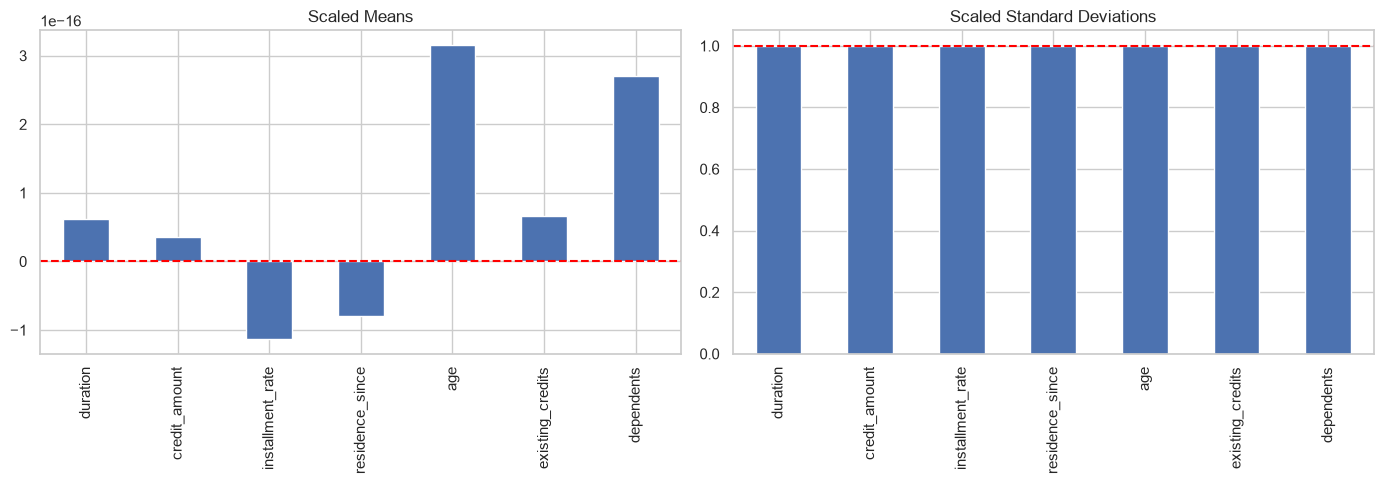

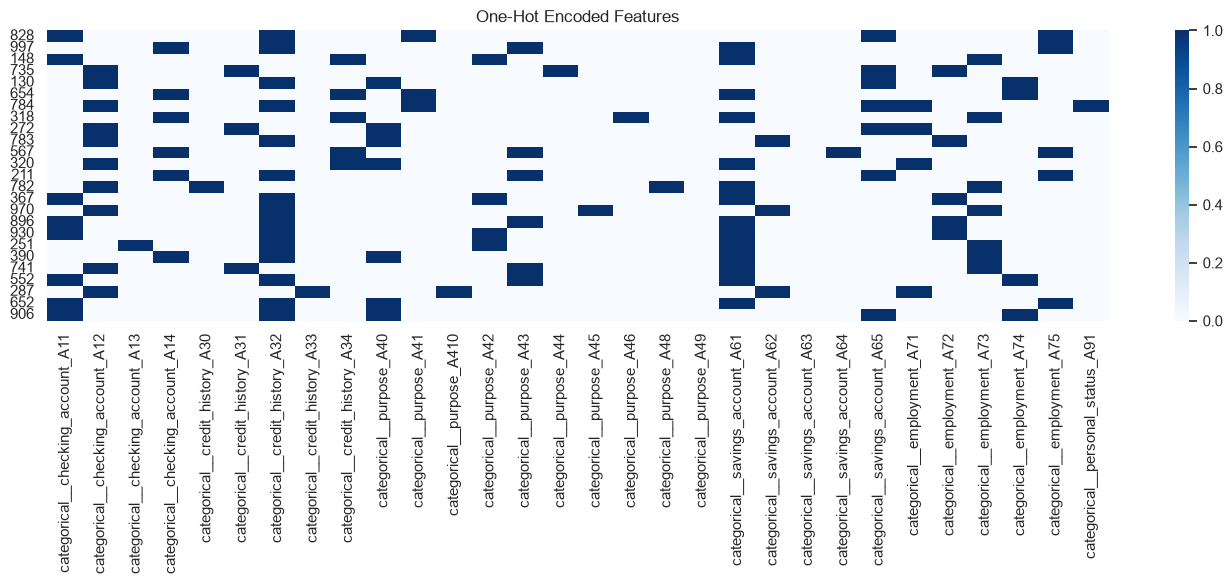

Only 0 and 1: True
Missing values: 0
Best parameters: {'knn__n_neighbors': 9, 'knn__p': 1, 'knn__weights': 'distance'}
Best CV Accuracy: 0.7538

Best configurations by F1:
    k   weights   distance  mean_test_bad_f1  mean_test_accuracy  \
5   5  distance  Manhattan             0.457               0.745   
4   5   uniform  Manhattan             0.455               0.746   
9   7  distance  Manhattan             0.440               0.753   
13  9  distance  Manhattan             0.439               0.754   
7   5  distance  Euclidean             0.434               0.744   
6   5   uniform  Euclidean             0.430               0.742   
0   3   uniform  Manhattan             0.429               0.736   
3   3  distance  Euclidean             0.427               0.726   
1   3  distance  Manhattan             0.426               0.732   
2   3   uniform  Euclidean             0.423               0.725   

    mean_test_balanced_accuracy  
5                         0.635  
4          

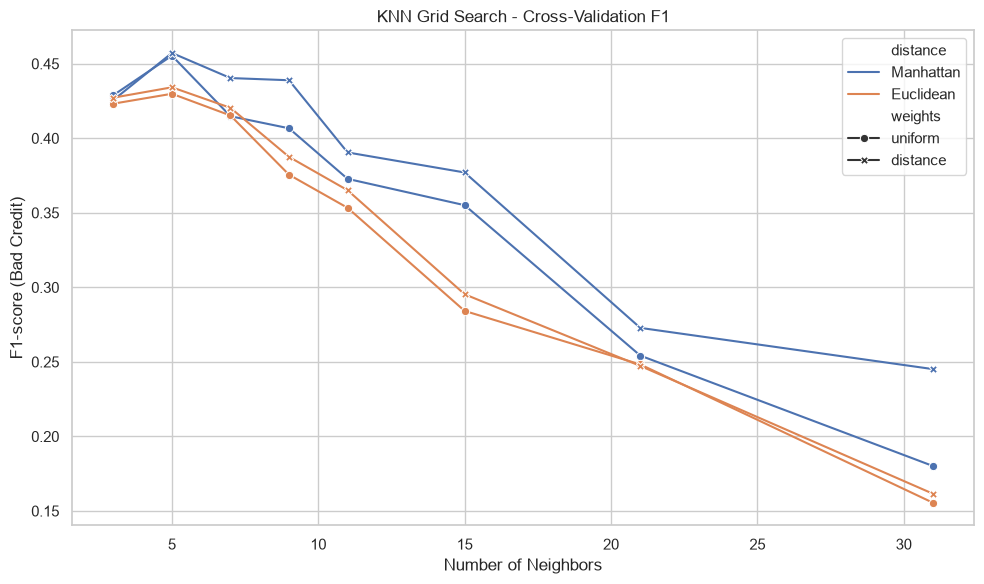

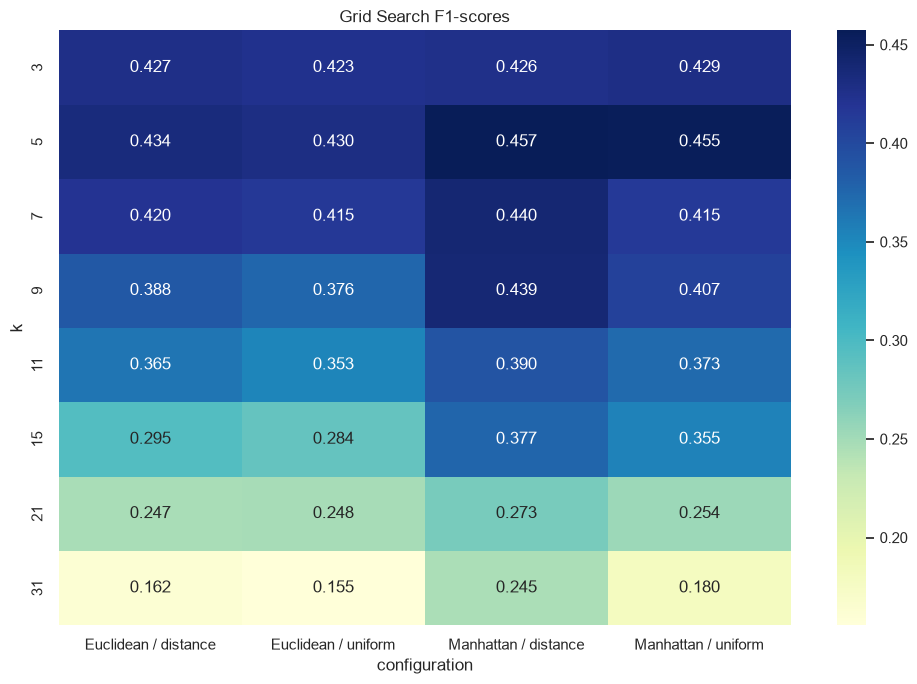

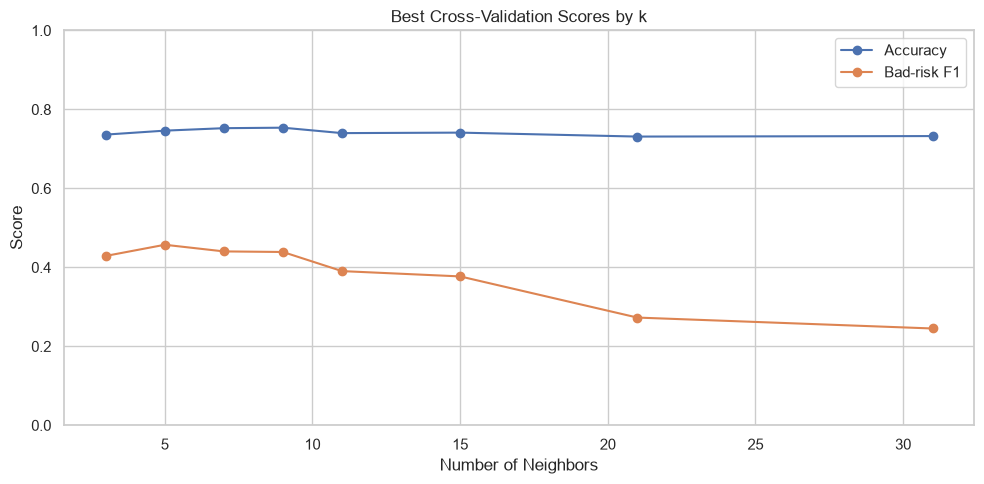


Final test results:
      Metric   Score
0   Accuracy  0.7450
1  Precision  0.6552
2     Recall  0.3167
3         F1  0.4270

Classification report:
              precision    recall  f1-score   support

 Good Credit       0.76      0.93      0.84       140
  Bad Credit       0.66      0.32      0.43        60

    accuracy                           0.74       200
   macro avg       0.71      0.62      0.63       200
weighted avg       0.73      0.74      0.71       200


Majority-class baseline accuracy: 0.7


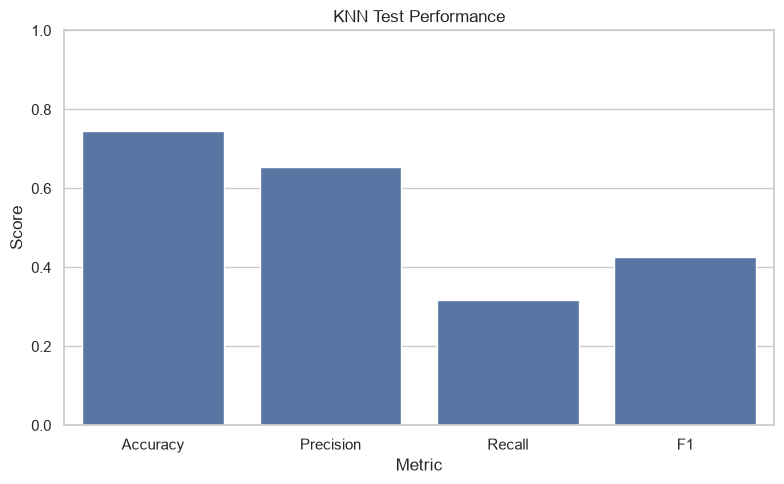

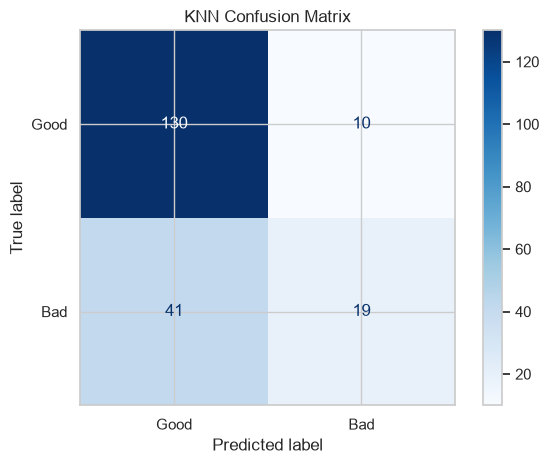

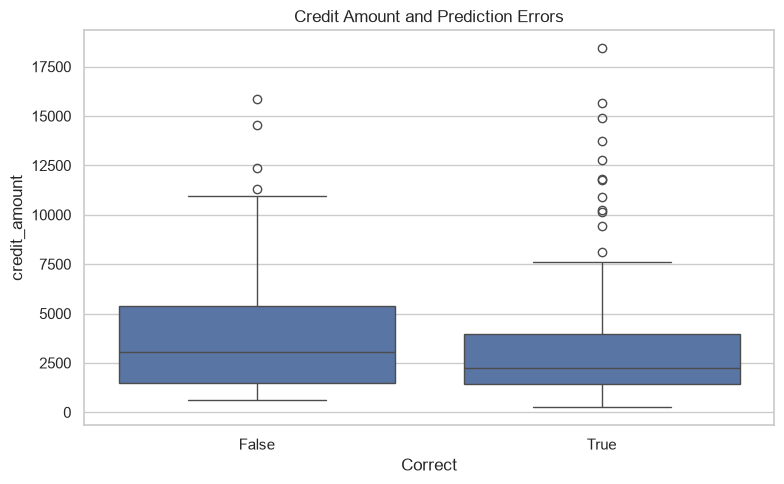

In [ ]:
# ---------------------------------------------------------
# 1. Imports
# ---------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
    make_scorer,
)

sns.set_theme(style="whitegrid")


# ---------------------------------------------------------
# 2. Load dataset
# ---------------------------------------------------------

DATA_PATH = Path.cwd() / "data" / "german.data"

column_names = [
    "checking_account",
    "duration",
    "credit_history",
    "purpose",
    "credit_amount",
    "savings_account",
    "employment",
    "installment_rate",
    "personal_status",
    "other_debtors",
    "residence_since",
    "property",
    "age",
    "other_installment_plans",
    "housing",
    "existing_credits",
    "job",
    "dependents",
    "telephone",
    "foreign_worker",
    "credit_risk",
]

df = pd.read_csv(DATA_PATH, sep=r"\s+", header=None, names=column_names)

X = df.drop(columns="credit_risk")
y = df["credit_risk"]

print("Dataset shape:", df.shape)
print("Features:", X.shape)
print("Target:", y.shape)


# ---------------------------------------------------------
# 3. Data inspection
# ---------------------------------------------------------

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

feature_summary = pd.DataFrame(
    {"Type": X.dtypes.astype(str), "Missing": X.isna().sum(), "Unique": X.nunique()}
)

print(feature_summary)
print("\nMissing values:", X.isna().sum().sum())
print("Duplicate rows:", X.duplicated().sum())
print("\nTarget distribution:")
print(y.value_counts().sort_index())


# ---------------------------------------------------------
# 4. Exploratory data analysis
# ---------------------------------------------------------

# Credit risk distribution

class_counts = y.value_counts().sort_index()

plt.figure(figsize=(8, 5))
sns.barplot(x=["Good Credit", "Bad Credit"], y=class_counts.values)
plt.title("Credit Risk Distribution")
plt.xlabel("Credit Risk")
plt.ylabel("Applicants")
plt.tight_layout()
plt.show()


# Numerical feature distributions

X[numeric_features].hist(figsize=(14, 9), bins=25, edgecolor="black")
plt.suptitle("Numerical Feature Distributions")
plt.tight_layout()
plt.show()


# Credit amount by risk class

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="credit_risk", y="credit_amount", order=[1, 2])
plt.title("Credit Amount by Risk Class")
plt.xlabel("Credit Risk (1 = Good, 2 = Bad)")
plt.ylabel("Credit Amount")
plt.tight_layout()
plt.show()


# Correlations between numerical features

plt.figure(figsize=(10, 8))
sns.heatmap(
    X[numeric_features].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0
)
plt.title("Numerical Feature Correlations")
plt.tight_layout()
plt.show()


# Credit amount and duration

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="duration",
    y="credit_amount",
    hue="credit_risk",
    palette={1: "green", 2: "red"},
    alpha=0.65,
)
plt.title("Credit Amount vs Duration")
plt.xlabel("Duration (Months)")
plt.ylabel("Credit Amount")
plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 5. Train/test split
# ---------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


# ---------------------------------------------------------
# 6. Preprocessing
# ---------------------------------------------------------

numeric_pipeline = Pipeline(
    [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
)

categorical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocessor = ColumnTransformer(
    [
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ]
)

# Fit a preprocessing copy for inspection.
# GridSearchCV will fit preprocessing independently in each fold.

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

processed_train = pd.DataFrame(
    X_train_processed, columns=feature_names, index=X_train.index
)

print("Features before:", X_train.shape[1])
print("Features after:", processed_train.shape[1])


# ---------------------------------------------------------
# 7. Check preprocessing
# ---------------------------------------------------------

scaled_numeric = processed_train[
    [col for col in feature_names if col.startswith("numeric__")]
].copy()

scaled_numeric.columns = numeric_features

encoded_data = processed_train[
    [col for col in feature_names if col.startswith("categorical__")]
]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=X_train[numeric_features], ax=axes[0])
axes[0].set_title("Before Scaling")
axes[0].tick_params(axis="x", rotation=45)

sns.boxplot(data=scaled_numeric, ax=axes[1])
axes[1].set_title("After Scaling")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


# Check scaled means and standard deviations

scaling_summary = pd.DataFrame(
    {"Mean": scaled_numeric.mean(), "Std": scaled_numeric.std(ddof=0)}
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

scaling_summary["Mean"].plot.bar(ax=axes[0], title="Scaled Means")
scaling_summary["Std"].plot.bar(ax=axes[1], title="Scaled Standard Deviations")

axes[0].axhline(0, color="red", linestyle="--")
axes[1].axhline(1, color="red", linestyle="--")

plt.tight_layout()
plt.show()


# Visualize one-hot encoding

plt.figure(figsize=(14, 6))

sns.heatmap(encoded_data.iloc[:25, :30], cmap="Blues", vmin=0, vmax=1)

plt.title("One-Hot Encoded Features")
plt.tight_layout()
plt.show()

print("Only 0 and 1:", encoded_data.isin([0, 1]).all().all())
print("Missing values:", processed_train.isna().sum().sum())


# ---------------------------------------------------------
# 8. KNN training and Grid Search
# ---------------------------------------------------------

model = Pipeline([("preprocessor", preprocessor), ("knn", KNeighborsClassifier())])

param_grid = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "bad_f1": make_scorer(f1_score, pos_label=2),
    "balanced_accuracy": "balanced_accuracy",
}

grid_search = GridSearchCV(
    model, param_grid, scoring=scoring, refit="accuracy", cv=cv, n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV Accuracy:", round(grid_search.best_score_, 4))


# Analyze all hyperparameter combinations

cv_results = pd.DataFrame(grid_search.cv_results_)

cv_results["k"] = cv_results["param_knn__n_neighbors"].astype(int)
cv_results["weights"] = cv_results["param_knn__weights"].astype(str)
cv_results["distance"] = cv_results["param_knn__p"].map(
    {1: "Manhattan", 2: "Euclidean"}
)

print("\nBest configurations by F1:")
print(
    cv_results[
        [
            "k",
            "weights",
            "distance",
            "mean_test_bad_f1",
            "mean_test_accuracy",
            "mean_test_balanced_accuracy",
        ]
    ]
    .sort_values("mean_test_bad_f1", ascending=False)
    .head(10)
    .round(3)
)


# F1-score for different values of k

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=cv_results,
    x="k",
    y="mean_test_bad_f1",
    hue="distance",
    style="weights",
    markers=True,
    dashes=False,
    estimator=None,
)

plt.title("KNN Grid Search - Cross-Validation F1")
plt.xlabel("Number of Neighbors")
plt.ylabel("F1-score (Bad Credit)")
plt.tight_layout()
plt.show()


# F1-score heatmap

cv_results["configuration"] = cv_results["distance"] + " / " + cv_results["weights"]

heatmap_data = cv_results.pivot(
    index="k", columns="configuration", values="mean_test_bad_f1"
)

plt.figure(figsize=(10, 7))
sns.heatmap(heatmap_data, annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("Grid Search F1-scores")
plt.tight_layout()
plt.show()


# Compare accuracy and F1 during cross-validation

score_comparison = (
    cv_results.groupby("k")[["mean_test_accuracy", "mean_test_bad_f1"]]
    .max()
    .rename(
        columns={"mean_test_accuracy": "Accuracy", "mean_test_bad_f1": "Bad-risk F1"}
    )
)

score_comparison.plot(marker="o", figsize=(10, 5))
plt.title("Best Cross-Validation Scores by k")
plt.xlabel("Number of Neighbors")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 9. Final evaluation
# ---------------------------------------------------------

best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=2)
recall = recall_score(y_test, y_pred, pos_label=2)
f1 = f1_score(y_test, y_pred, pos_label=2)

metrics = pd.DataFrame(
    {
        "Metric": ["Accuracy", "Precision", "Recall", "F1"],
        "Score": [accuracy, precision, recall, f1],
    }
)

print("\nFinal test results:")
print(metrics.round(4))

print("\nClassification report:")
print(
    classification_report(
        y_test, y_pred, labels=[1, 2], target_names=["Good Credit", "Bad Credit"]
    )
)


# Compare against a simple majority-class baseline

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

print(
    "\nMajority-class baseline accuracy:",
    round(accuracy_score(y_test, baseline_pred), 4),
)


# Evaluation metrics plot

plt.figure(figsize=(8, 5))
sns.barplot(data=metrics, x="Metric", y="Score")
plt.title("KNN Test Performance")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


# Confusion matrix

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=[1, 2], display_labels=["Good", "Bad"], cmap="Blues"
)

plt.title("KNN Confusion Matrix")
plt.tight_layout()
plt.show()


# Inspect incorrect predictions

predictions = X_test.copy()
predictions["Actual"] = y_test
predictions["Predicted"] = y_pred
predictions["Correct"] = y_test == y_pred

plt.figure(figsize=(8, 5))
sns.boxplot(data=predictions, x="Correct", y="credit_amount")
plt.title("Credit Amount and Prediction Errors")
plt.tight_layout()
plt.show()